# Bear pretraining-checkpoint grid — `20260828_ckptgrid-bear_160m`

End-to-end analysis of the **completed** bear pretraining-checkpoint-grid
campaign on PolyPythia-160M. Behaviour-only (no CKA / geometry). Frozen
teacher recipe `ep5_lr5e-5_r128a128`; frozen student recipe
`lmb1.0_b1.0_lora_lr4e-4_e1_r8a16`. Grid arm: 168 cells × 3 leaves + 42
controls. Joint arm: 90 cells × 3 leaves + 72 controls. 108 teachers.
Teachers share this run-set id.

This notebook is **read-only** on cached `results/` + `logs/`. It does
**not** retrain, does **not** re-run bootstraps, and does **not** write
under `output_root`. Paths resolve from `configs/paths/paths_local.yaml`
via `analysis.setup.bootstrap`.

Pre-registration: `docs/PREREG_CKPT_XGRID.md`. Constants:
`subliminal_learning.campaign.ckptgrid_plan`. Claim math:
`subliminal_learning.campaign.ckptgrid_metrics`. Plan:
`.cursor/plans/bear_checkpoint_grid_campaign_7e121636.plan.md`.

**How to run**
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_ckpt_grid_bear.ipynb` and run all cells top-to-bottom.

### Reading guide

- `delta = p_target − matched control mean`. Controls match on
  `(student_base, student_step)`. Difference of two probabilities, so
  roughly (−1, 1); `0` = no subliminal transfer above the
  untrained-base-teacher control.
- `grid_delta.csv` rows with `level='agg'` are **already means over 3
  leaves** (`n_leaves == 3` on every agg row). Never re-average them as
  if they were leaves. Use `level='leaf'` when you need per-leaf spread.
- `grid_delta.csv` holds the **primary endpoint only** (`test` / `prob`).
  The other three prompt sets live **only** in `grid_delta_robustness.csv`.
  Never pool prompt sets into a G1–G9 figure.
- Never pool `arm='grid'` with `arm='joint'`. The grid arm is
  `original ← original` (12 teacher × 14 student = 168 cells). The joint
  arm is 15 base pairings × 6 rungs = 90 cells, diagonal-only in rung
  (`student_step == teacher_step`).
- `claims.json` `strong_teacher_step` is the G1 argmax. The
  student-marginal slice is taken at that teacher rung; the
  teacher-marginal slice at student rung 143000.
- Cell labels: `SI_SS` same-init/same-stream, `SI_DS`
  same-init/different-stream, `DI_DS` different-init/different-stream.
  There is no `DI_SS` in this campaign.
- Drop rows with `degenerate == True` from efficiency / asymmetry /
  penalty figures, and **print how many you dropped** rather than
  silently filtering.
- No silent NaN fills. Missing grid cells stay NaN and must read as
  "unrun", not 0.
- Each figure is followed by a **Reading this figure** cell: the
  question it answers, the axes, how the metric is computed, the trend
  on *this* run, and what it does and does not support. Final claims
  are in **§15**.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Inventory & coverage vs plan |
| 1 | Provenance (teacher gate, state, prefetch, quarantine, claims) |
| 2 | Fig1 — G1 teacher acquisition curve |
| 3 | Fig2 — headline grid heatmap |
| 4 | Fig3 — G2/G3 marginals |
| 5 | Fig4 — matched-checkpoint ridge (**exploratory**) |
| 6 | Fig5 — G3 dose-response and efficiency |
| 7 | Fig6 — G4 diagonal dose vs maturity |
| 8 | Fig7 — G5 mismatch asymmetry and retention |
| 9 | Fig8 — G6 uncensored onset |
| 10 | Fig9 — G7 joint-vs-data bracketing |
| 11 | Fig10 — G8 cross-init penalty |
| 12 | Fig11 — G9 concordance with breadth4 |
| 13 | Fig12 — capability confound / quarantine |
| 14 | Fig13 — prompt-set robustness |
| 15 | Claims board + takeaways (from JSON + frames) |
| 16 | How to extend |

### Explicit exclusions

- CKA / geometry / probes / weight-space (out of scope this stage —
  deferred until EleutherAI's retrained weight-seeds land).
- Weight-seed bases (seed-audit defect; those Hub repos are not an init
  ablation).
- Crossed variance anchors.
- Cat-ladder reanalysis.
- Teacher adapter internals.

### Metric cheat-sheet

Formulas match `ckptgrid_metrics` and prereg §6. Ranges are theoretical,
not this run’s numbers (those print from CSVs below).

| ID | Answers | Values | Calculation | Example reading | Notes |
|---|---|---|---|---|---|
| `delta` | Did GKD from this teacher raise bear preference above a matched **base-teacher** control? | Difference of two probabilities: theoretically (−1, 1). | `p_target − control_mean` (`ckptgrid_metrics.build_grid_delta`). Control matched on `(student_base, student_step)`. Primary `test`/`prob`. | `0` = no SL above control. Positive = more last-token p(`" bear"`) than control. | Agg rows are already 3-leaf means. Never pool prompt sets or arms. |
| `teacher_p_target` | How strong is the teacher’s bear preference at this pretraining rung? | [0, 1] | Per-rung mean of teacher `p_target` over 3 ftseeds (`build_teacher_curve` → `teacher_mean`). | `0` = no bear preference. Near 1 = almost all mass on the target token. | G1 dose axis. Overlay `control_mean` is the untrained base at the same rung. |
| `efficiency` | How much transfer per unit of teacher strength? | Unbounded; NaN when `teacher_p_target ≤ 0`. | `delta / teacher_p_target` (`build_efficiency`). `degenerate=True` if the denominator is missing or ≤ 0. | `1` = student delta equals teacher p_target. `0` = no transfer despite a positive teacher. | Drop degenerates and print the count. G3/G4 input. |
| `asymmetry` | Does a mature teacher → young student beat the swapped pair? | Difference of two deltas: theoretically (−2, 2). | `delta(teacher@hi → student@lo) − delta(teacher@lo → student@hi)` (`build_asymmetry`). | `0` = symmetric degradation. Positive = mature-teacher/young-student wins. | G5. Drop `degenerate`. |
| `retention` | How much of the diagonal’s transfer survives a rung mismatch? | Unbounded; NaN if the matching diagonal delta is ≤ 0. | Off-diagonal delta / diagonal delta at that student rung (`build_asymmetry`). | `1` = mismatch keeps the full diagonal. `0` = mismatch wipes it. | Two series: mature→young and young→mature. |
| `penalty` | How large is the cross-init deficit vs same-init joint anchors? | (−∞, 1]; NaN if the anchor mean is ≤ 0. | `1 − mean_cross / mean_anchor` (`build_penalty_trend`). | `0` = cross equals anchor. Positive = cross weaker. Negative = cross stronger. | G8. Joint rungs only. Drop `degenerate`. |
| bracketing gap | Upper bound on the initialization effect at a joint rung. | Difference of two mean deltas. | `mean(SI_DS original↔data-seed1) − mean(DI_DS original↔seedN)` (`build_bracketing`). | `0` = stream-only and init+stream cells match. Positive = stream-only larger. | **Not** a single-factor init estimate. Robustness contrasts are labelled, not pooled. |
| `onset_step` | First student rung where transfer clears control + k·SD for two consecutive rungs. | A scored student rung, or null if censored. | `build_onset` under the G1-strong teacher; `sd_multiple=2`, `consecutive=2`. | Earliest scored rung = lower bound on detectability, not a resolved onset. | G6. Markers are 0.22% and 1% of 143000. |
| `perplexity_ratio` | Did GKD blow up the student’s Pile PPL vs its own base? | (0, ∞). `1` = unchanged. | Student PPL / base PPL. Flagged when `> QUARANTINE_PPL_RATIO_MAX` (`quarantine_frame` in the results pipeline). | Ratio `> 5` is the leaf quarantine bound. | 34 rows on disk, all `scope='perplexity_ratio'`. Labelled, never silently dropped. |


## Setup


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.patches import Patch, Rectangle

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import ckptgrid_plan as plan
from subliminal_learning.gkd.layout import GKD_STUDENTS_SUBDIR
from subliminal_learning.sdf.layout import SDF_TEACHERS_SUBDIR

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

PROMPT_SET = plan.PRIMARY_PROMPT_SET
STRONG_TEACHER_STEP: int | None = None
ARM = "grid"
SHOW_QUARANTINE = True
ROBUSTNESS_SETS = list(plan.EVAL_PROMPT_SETS)

TREE = OUTPUT_ROOT / GKD_STUDENTS_SUBDIR / plan.RUN_SET_ID
RES = TREE / "results"
LOGS = TREE / "logs"
TEACHER_TREE = OUTPUT_ROOT / SDF_TEACHERS_SUBDIR / plan.TEACHER_RUN_SET_ID

assert TREE.exists(), f"missing behaviour tree: {TREE}"
assert RES.exists(), f"missing results/: {RES}"
assert LOGS.exists(), f"missing logs/: {LOGS}"
assert "/mnt/ssd-1/" not in str(OUTPUT_ROOT), (
    f"refusing slow SSD-1 output_root: {OUTPUT_ROOT}"
)
if TREE.is_symlink():
    print("WARNING: TREE is a symlink →", TREE.resolve())
if TEACHER_TREE.is_symlink():
    print("WARNING: TEACHER_TREE is a symlink →", TEACHER_TREE.resolve())

print("ROOT         :", ROOT)
print("OUTPUT_ROOT  :", OUTPUT_ROOT)
print("TREE         :", TREE)
print("RES          :", RES)
print("LOGS         :", LOGS)
print("TEACHER_TREE :", TEACHER_TREE)
print("RUN_SET      :", plan.RUN_SET_ID)
print("teacher tag  :", plan.TEACHER_PARAM_TAG_LORA)
print("student tag  :", plan.STUDENT_GKD_TAG)
print("animals      :", plan.ANIMALS)
print("grid base    :", plan.GRID_BASE)
print("joint bases  :", plan.JOINT_SEED_BASES, plan.DATA_SEED_BASE)
print("teacher rungs:", plan.TEACHER_RUNGS)
print("student rungs:", plan.STUDENT_RUNGS)
print("joint rungs  :", plan.JOINT_RUNGS)
print("prompt sets  :", plan.EVAL_PROMPT_SETS)
print("primary      :", plan.PRIMARY_PROMPT_SET, plan.PRIMARY_SCORING)
print("knobs        : PROMPT_SET=", PROMPT_SET, "ARM=", ARM)
print("             : STRONG_TEACHER_STEP=", STRONG_TEACHER_STEP)
print("             : SHOW_QUARANTINE=", SHOW_QUARANTINE)


def scope(df: pd.DataFrame, note: str = "") -> None:
    """Print a compact SCOPE line (does not assume teacher-sweep columns)."""
    bits = [f"n={len(df)}"]
    for col in (
        "arm",
        "level",
        "cell",
        "set",
        "scoring",
        "student_base",
        "teacher_base",
        "student_step",
        "teacher_step",
        "slice",
        "contrast",
        "ftseed",
        "gseed",
    ):
        if col in df.columns:
            bits.append(f"{col}={df[col].nunique(dropna=False)}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


def step_x(step) -> float:
    """Log-x helper: plot step 0 at 0.5 so it is visible on a log axis."""
    s = float(step)
    return 0.5 if s <= 0 else s


def add_step_x(df: pd.DataFrame, src: str = "step") -> pd.DataFrame:
    out = df.copy()
    out["x"] = [step_x(v) for v in out[src]]
    return out


def claim_record(cid: str) -> dict:
    for rec in CLAIMS["claims"]:
        if rec["id"] == cid:
            return rec
    raise KeyError(cid)


def strong_teacher_step() -> int:
    if STRONG_TEACHER_STEP is not None:
        return int(STRONG_TEACHER_STEP)
    return int(CLAIMS["strong_teacher_step"])


def grid_agg(arm: str) -> pd.DataFrame:
    """Primary-endpoint agg rows for one arm, steps coerced to int."""
    out = GRID_DELTA.loc[
        (GRID_DELTA["level"].astype(str) == "agg")
        & (GRID_DELTA["arm"].astype(str) == arm)
    ].copy()
    out["student_step"] = out["student_step"].astype(int)
    out["teacher_step"] = out["teacher_step"].astype(int)
    return out


def grid_pivot(
    frame: pd.DataFrame,
    *,
    value: str = "delta",
    index: str = "student_step",
    columns: str = "teacher_step",
) -> pd.DataFrame:
    """One value per (student, teacher) rung. Gaps stay NaN (unrun, not 0)."""
    piv = frame.pivot(index=index, columns=columns, values=value)
    return piv.reindex(index=list(plan.STUDENT_RUNGS), columns=list(plan.TEACHER_RUNGS))


def diverging_norm(values, vcenter: float = 0.0) -> TwoSlopeNorm:
    """Shared diverging colour scale with 0 as the neutral colour."""
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    lo = float(np.min(finite)) if finite.size else -0.1
    hi = float(np.max(finite)) if finite.size else 0.1
    pad = 1e-6
    if lo >= vcenter:
        lo = vcenter - pad
    if hi <= vcenter:
        hi = vcenter + pad
    return TwoSlopeNorm(vmin=lo, vcenter=vcenter, vmax=hi)


def drop_degenerate(df: pd.DataFrame, note: str) -> pd.DataFrame:
    """Drop `degenerate` rows and print how many were removed."""
    n_drop = int(df["degenerate"].astype(bool).sum())
    print(f"dropped {n_drop} of {len(df)} {note} rows (degenerate)")
    return df.loc[~df["degenerate"].astype(bool)].copy()


def fmt_num(value, nd: int = 4) -> str:
    """Round a claim statistic for an in-figure label (full floats are unreadable)."""
    try:
        return f"{float(value):.{nd}f}"
    except (TypeError, ValueError):
        return str(value)


def fmt_ci(pair, nd: int = 4) -> str:
    """Format a two-element CI as ``[lo, hi]`` at `nd` decimals."""
    if pair is None:
        return "n/a"
    lo, hi = pair
    return f"[{fmt_num(lo, nd)}, {fmt_num(hi, nd)}]"


def quarantine_pairs() -> set[tuple[int, int]]:
    return set(
        zip(QUAR["step"].astype(int), QUAR["teacher_step"].astype(int), strict=True)
    )


def mark_diagonal(ax, index, columns) -> None:
    idx = {int(v): i for i, v in enumerate(index)}
    cols = {int(v): j for j, v in enumerate(columns)}
    for step in plan.TEACHER_RUNGS:
        if step in idx and step in cols:
            i, j = idx[step], cols[step]
            ax.add_patch(
                Rectangle(
                    (j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="k", lw=1.4
                )
            )


def mark_quarantine(ax, index, columns) -> int:
    idx = {int(v): i for i, v in enumerate(index)}
    cols = {int(v): j for j, v in enumerate(columns)}
    n_mark = 0
    for student_step, teacher_step in quarantine_pairs():
        if student_step in idx and teacher_step in cols:
            i, j = idx[student_step], cols[teacher_step]
            ax.add_patch(
                Rectangle(
                    (j - 0.5, i - 0.5),
                    1,
                    1,
                    fill=False,
                    hatch="///",
                    edgecolor="0.2",
                    lw=0.6,
                )
            )
            n_mark += 1
    return n_mark


ROOT         : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT  : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
TREE         : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260828_ckptgrid-bear_160m
RES          : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260828_ckptgrid-bear_160m/results
LOGS         : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260828_ckptgrid-bear_160m/logs
TEACHER_TREE : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260828_ckptgrid-bear_160m
RUN_SET      : 20260828_ckptgrid-bear_160m
teacher tag  : ep5_lr5e-5_r128a128
student tag  : lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
animals      : ('bear',)
grid base    : original
joint bases  : ('seed1', 'seed2', 'seed3') data-seed1
teacher rungs: (512, 1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000)
student rungs: (128, 256, 512, 1000, 2000, 4000, 8000, 16000, 32000, 48000, 6

## Load artifacts

One cell: the ten `plan.RESULTS_*` CSVs, `claims.json`, the four log
JSONs, and `CAMPAIGN_DONE`. Fail loud if a required file is missing.


In [2]:
def _read_csv(name: str) -> pd.DataFrame:
    path = RES / name
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def _read_json(dirpath: Path, name: str) -> dict:
    path = dirpath / name
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


RESULT_FILES = (
    plan.RESULTS_TEACHER_CURVE_CSV,
    plan.RESULTS_GRID_DELTA_CSV,
    plan.RESULTS_GRID_DELTA_ROBUSTNESS_CSV,
    plan.RESULTS_GRID_MARGINALS_CSV,
    plan.RESULTS_GRID_EFFICIENCY_CSV,
    plan.RESULTS_GRID_ASYMMETRY_CSV,
    plan.RESULTS_JOINT_BRACKETING_CSV,
    plan.RESULTS_GRID_PENALTY_CSV,
    plan.RESULTS_GRID_ONSET_CSV,
    plan.RESULTS_GRID_QUARANTINE_CSV,
    plan.RESULTS_CLAIMS_JSON,
)
for name in RESULT_FILES:
    assert (RES / name).exists(), f"missing {RES / name}"

for name in (
    plan.CAMPAIGN_DONE_FILE,
    plan.CAMPAIGN_STATE_FILE,
    plan.PREFLIGHT_REPORT,
    plan.TEACHER_GATE_REPORT,
    plan.PREFETCH_MANIFEST,
):
    assert (LOGS / name).exists(), f"missing {LOGS / name}"

TEACHER_CURVE = _read_csv(plan.RESULTS_TEACHER_CURVE_CSV)
GRID_DELTA = _read_csv(plan.RESULTS_GRID_DELTA_CSV)
GRID_ROB = _read_csv(plan.RESULTS_GRID_DELTA_ROBUSTNESS_CSV)
MARGINALS = _read_csv(plan.RESULTS_GRID_MARGINALS_CSV)
EFFICIENCY = _read_csv(plan.RESULTS_GRID_EFFICIENCY_CSV)
ASYMMETRY = _read_csv(plan.RESULTS_GRID_ASYMMETRY_CSV)
BRACKETING = _read_csv(plan.RESULTS_JOINT_BRACKETING_CSV)
PENALTY = _read_csv(plan.RESULTS_GRID_PENALTY_CSV)
ONSET = _read_csv(plan.RESULTS_GRID_ONSET_CSV)
QUAR = _read_csv(plan.RESULTS_GRID_QUARANTINE_CSV)
CLAIMS = _read_json(RES, plan.RESULTS_CLAIMS_JSON)
STATE = _read_json(LOGS, plan.CAMPAIGN_STATE_FILE)
PREFLIGHT = _read_json(LOGS, plan.PREFLIGHT_REPORT)
GATE = _read_json(LOGS, plan.TEACHER_GATE_REPORT)
PREFETCH = _read_json(LOGS, plan.PREFETCH_MANIFEST)

done_path = LOGS / plan.CAMPAIGN_DONE_FILE
DONE_TEXT = done_path.read_text().strip()
print("CAMPAIGN_DONE:", DONE_TEXT)

print("resolved RES files:")
for path in sorted(RES.iterdir()):
    if path.is_file():
        print(f"  {path.name:36s} {path.stat().st_size:9d} B")


CAMPAIGN_DONE: campaign 20260828_ckptgrid-bear_160m finished 2026-08-30T01:41:36Z
resolved RES files:
  claims.json                               4679 B
  grid_asymmetry.csv                       12603 B
  grid_delta.csv                          129617 B
  grid_delta_robustness.csv               393440 B
  grid_efficiency.csv                      25341 B
  grid_marginals.csv                        4594 B
  grid_onset.csv                            1055 B
  grid_penalty.csv                           745 B
  grid_quarantine.csv                       3335 B
  joint_bracketing.csv                      1263 B
  teacher_curve.csv                         1415 B


## 0. Inventory & coverage

**What this measures.** Disk vs plan: 168 grid agg cells, 90 joint agg
cells, 504 + 270 leaves, 12 teacher rungs, 14 student rungs, 6 joint
rungs, primary `test`/`prob` uniqueness, robustness endpoints, cell
labels, joint pairings, animals. Fail loud if the primary frame is empty.


In [3]:
if GRID_DELTA.empty:
    raise RuntimeError("primary grid_delta frame is empty — cannot score G1–G9")

prim = GRID_DELTA.loc[
    (GRID_DELTA["set"] == plan.PRIMARY_PROMPT_SET)
    & (GRID_DELTA["scoring"] == plan.PRIMARY_SCORING)
]
if prim.empty:
    raise RuntimeError("primary test/prob frame is empty — cannot score G1–G9")

scope(GRID_DELTA, "grid_delta all levels/arms")
scope(prim, "PRIMARY test/prob")

agg = GRID_DELTA.loc[GRID_DELTA["level"] == "agg"]
leaf = GRID_DELTA.loc[GRID_DELTA["level"] == "leaf"]
agg_g = agg.loc[agg["arm"] == "grid"]
agg_j = agg.loc[agg["arm"] == "joint"]
leaf_g = leaf.loc[leaf["arm"] == "grid"]
leaf_j = leaf.loc[leaf["arm"] == "joint"]

print("agg grid", len(agg_g), "expected 168")
print("agg joint", len(agg_j), "expected 90")
print("leaf grid", len(leaf_g), "expected 504")
print("leaf joint", len(leaf_j), "expected 270")
assert len(agg_g) == 12 * 14
assert len(agg_j) == 15 * 6
assert len(leaf_g) == 12 * 14 * 3
assert len(leaf_j) == 15 * 6 * 3
print("agg n_leaves", sorted(agg["n_leaves"].unique().tolist()))
print("leaf n_leaves", sorted(leaf["n_leaves"].unique().tolist()))
assert set(agg["n_leaves"].tolist()) == {3}

print("teacher rungs (curve):", sorted(TEACHER_CURVE["step"].astype(int).unique()))
print("teacher rungs (grid):", sorted(agg_g["teacher_step"].astype(int).unique()))
print("student rungs (grid):", sorted(agg_g["student_step"].astype(int).unique()))
print("joint rungs:", sorted(agg_j["student_step"].astype(int).unique()))
assert sorted(TEACHER_CURVE["step"].astype(int).unique()) == list(plan.TEACHER_RUNGS)
assert sorted(agg_g["teacher_step"].astype(int).unique()) == list(plan.TEACHER_RUNGS)
assert sorted(agg_g["student_step"].astype(int).unique()) == list(plan.STUDENT_RUNGS)
assert sorted(agg_j["student_step"].astype(int).unique()) == list(plan.JOINT_RUNGS)
assert bool((agg_j["student_step"].astype(int) == agg_j["teacher_step"].astype(int)).all())

print("set × scoring:\n", GRID_DELTA.groupby(["set", "scoring"]).size())
assert set(GRID_DELTA["set"]) == {plan.PRIMARY_PROMPT_SET}
assert set(GRID_DELTA["scoring"]) == {plan.PRIMARY_SCORING}

print("robustness set × scoring:\n", GRID_ROB.groupby(["set", "scoring"]).size())
rob_keys = set(zip(GRID_ROB["set"], GRID_ROB["scoring"], strict=True))
assert rob_keys == {
    ("favorite", "prob"),
    ("off_topic", "prob"),
    ("storytelling", "sample"),
}
print("robustness rows", len(GRID_ROB), "expected", 3 * len(GRID_DELTA))
assert len(GRID_ROB) == 3 * len(GRID_DELTA)

print("cells:", GRID_DELTA["cell"].value_counts(dropna=False).to_dict())
assert "DI_SS" not in set(GRID_DELTA["cell"].astype(str))
print("curve bases:", sorted(TEACHER_CURVE["base"].unique().tolist()))
assert set(TEACHER_CURVE["base"]) == {plan.GRID_BASE}
print("plan.ANIMALS:", plan.ANIMALS)
assert plan.ANIMALS == ("bear",)

joint_pairs = (
    agg_j.groupby(["student_base", "teacher_base", "cell"], dropna=False)
    .size()
    .reset_index(name="n_agg")
)
print("joint-arm pairing table (agg):")
display(joint_pairs)
assert len(joint_pairs) == 15

print("SCOPE summary: 168 grid agg | 90 joint agg | 504+270 leaves | 12×14×6 rungs")


SCOPE: n=1032 | arm=2 | level=2 | cell=3 | set=1 | scoring=1 | student_base=5 | teacher_base=5 | student_step=14 | teacher_step=12 | ftseed=4 | gseed=1 | grid_delta all levels/arms
SCOPE: n=1032 | arm=2 | level=2 | cell=3 | set=1 | scoring=1 | student_base=5 | teacher_base=5 | student_step=14 | teacher_step=12 | ftseed=4 | gseed=1 | PRIMARY test/prob
agg grid 168 expected 168
agg joint 90 expected 90
leaf grid 504 expected 504
leaf joint 270 expected 270
agg n_leaves [3]
leaf n_leaves [1]
teacher rungs (curve): [np.int64(512), np.int64(1000), np.int64(2000), np.int64(4000), np.int64(8000), np.int64(16000), np.int64(32000), np.int64(48000), np.int64(64000), np.int64(96000), np.int64(128000), np.int64(143000)]
teacher rungs (grid): [np.int64(512), np.int64(1000), np.int64(2000), np.int64(4000), np.int64(8000), np.int64(16000), np.int64(32000), np.int64(48000), np.int64(64000), np.int64(96000), np.int64(128000), np.int64(143000)]
student rungs (grid): [np.int64(128), np.int64(256), np.int

,student_base,teacher_base,cell,n_agg
0,data-seed1,original,SI_DS,6
1,data-seed1,seed1,DI_DS,6
2,original,data-seed1,SI_DS,6
3,original,seed1,DI_DS,6
4,original,seed2,DI_DS,6
5,original,seed3,DI_DS,6
6,seed1,data-seed1,DI_DS,6
7,seed1,original,DI_DS,6
8,seed1,seed1,SI_SS,6
9,seed1,seed2,DI_DS,6


SCOPE summary: 168 grid agg | 90 joint agg | 504+270 leaves | 12×14×6 rungs


## 1. Provenance

**What this measures.** Teacher-gate checks, `campaign_state.json`
transitions, prefetch-manifest ref count, quarantine tier/scope summary,
and `claims.json` identity fields. Numbers come from the next cell —
not from this markdown.


In [4]:
print("teacher_gate passed:", GATE.get("passed"))
print("ok_original_rungs:", GATE.get("ok_original_rungs"))
print("curve_span:", GATE.get("curve_span"))
print("thresholds:", GATE.get("thresholds"))
gate_checks = pd.DataFrame(GATE.get("checks") or [])
display(gate_checks)
n_ok = len(GATE.get("ok_original_rungs") or [])
print(f"min_ok_rungs live: {n_ok}/{len(plan.TEACHER_RUNGS)}")
print(
    "curve_span vs min:",
    GATE.get("curve_span"),
    ">=",
    plan.TEACHER_GATE_MIN_CURVE_SPAN,
)

transitions = STATE.get("transitions") or {}
state_rows = []
for name, payload in transitions.items():
    state_rows.append(
        {
            "transition": name,
            "at": (payload or {}).get("at"),
            "keys": sorted((payload or {}).keys()),
        }
    )
display(pd.DataFrame(state_rows))

print("prefetch n_refs:", PREFETCH.get("n_refs"), "refs list", len(PREFETCH.get("refs") or []))
print("preflight n_refs:", PREFLIGHT.get("n_refs"), "prereg:", PREFLIGHT.get("prereg"))

print("quarantine scope:\n", QUAR["scope"].value_counts(dropna=False))
print("quarantine tier:\n", QUAR["tier"].value_counts(dropna=False))
print("quarantine reason:\n", QUAR["reason"].value_counts(dropna=False))
print("quarantine rows:", len(QUAR), "unique (student, teacher) cells:", len(quarantine_pairs()))

print("claims.at:", CLAIMS.get("at"))
print("claims.run_set_id:", CLAIMS.get("run_set_id"))
print("claims.breadth4_run_set_id:", CLAIMS.get("breadth4_run_set_id"))
print("claims.primary_endpoint:", CLAIMS.get("primary_endpoint"))
print("claims.strong_teacher_step:", CLAIMS.get("strong_teacher_step"))
assert CLAIMS.get("run_set_id") == plan.RUN_SET_ID
print("CAMPAIGN_DONE:", DONE_TEXT)


teacher_gate passed: True
ok_original_rungs: [512, 1000, 2000, 4000, 8000, 16000, 32000, 48000, 64000, 96000, 128000, 143000]
curve_span: 0.5483061361980314
thresholds: {'sd_multiple': 5.0, 'abs_min': 0.02, 'min_ok_rungs': 6, 'min_curve_span': 0.05}


,check,passed,detail,value,threshold
0,min_ok_rungs,True,"12 original-base ok rungs [512, 1000, 2000, 40...",12.000000,6.00
1,curve_span,True,original-base curve span 0.5483 (need >= 0.05),0.548306,0.05


min_ok_rungs live: 12/12
curve_span vs min: 0.5483061361980314 >= 0.05


,transition,at,keys
0,preflight,2026-08-28T20:06:44Z,"[at, train_yamls, verify_yamls]"
1,submit_p1,2026-08-28T20:06:44Z,"[at, n_teacher_eval_jobs, n_teacher_jobs]"
2,teacher_gate,2026-08-28T21:41:48Z,"[at, curve_span, ok_original_rungs, passed, re..."
3,submit_p2_p3,2026-08-28T21:41:48Z,"[at, grid_control_yamls, grid_student_yamls, j..."
4,submit_p4,2026-08-30T00:01:06Z,"[at, n_eval_jobs, verify_yamls]"
5,finalize,2026-08-30T01:41:36Z,"[at, results]"


prefetch n_refs: 38 refs list 38
preflight n_refs: 38 prereg: docs/PREREG_CKPT_XGRID.md
quarantine scope:
 scope
perplexity_ratio    34
Name: count, dtype: int64
quarantine tier:
 tier
quarantine    34
Name: count, dtype: int64
quarantine reason:
 reason
perplexity_ratio>5    34
Name: count, dtype: int64
quarantine rows: 34 unique (student, teacher) cells: 12
claims.at: 2026-09-02T21:44:50Z
claims.run_set_id: 20260828_ckptgrid-bear_160m
claims.breadth4_run_set_id: 20260809_breadth4_160m
claims.primary_endpoint: {'prompt_set': 'test', 'scoring': 'prob'}
claims.strong_teacher_step: 8000
CAMPAIGN_DONE: campaign 20260828_ckptgrid-bear_160m finished 2026-08-30T01:41:36Z


## 2. Fig1 — G1 teacher acquisition curve

**What this measures.** Original-base teacher bear preference vs
pretraining step. This is the dose axis every later figure normalizes
against, and the reason the G1 argmax is “the strong teacher”.


SCOPE: n=12 | teacher_curve


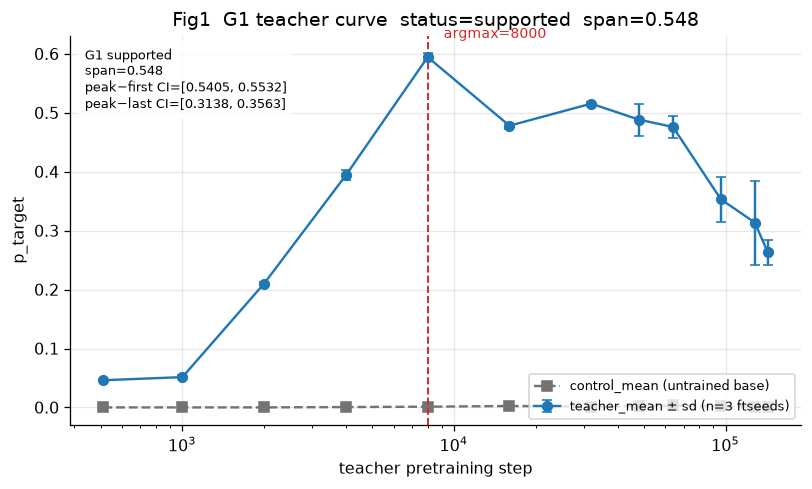

G1 record:
{'id': 'G1', 'operationalization': 'interior argmax AND span >= 0.05, with peak−endpoint bootstrap CIs excluding 0 at both ends', 'statistic': {'argmax_step': 8000, 'argmax_interior': True, 'span': 0.5483061361980314, 'peak_minus_first_ci': [0.5405350210476589, 0.5531881546680816], 'peak_minus_last_ci': [0.31380398557521405, 0.35628020752780143]}, 'threshold': {'min_span': 0.05, 'ci': 0.95}, 'status': 'supported', 'reason': None}


In [5]:
g1 = claim_record("G1")
scope(TEACHER_CURVE, "teacher_curve")
curve = add_step_x(TEACHER_CURVE, "step")
argmax = int(curve["argmax_step"].iloc[0])
span = float(curve["span"].iloc[0])
stat = g1.get("statistic") or {}
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.errorbar(
    curve["x"],
    curve["teacher_mean"],
    yerr=curve["teacher_sd"],
    fmt="o-",
    color="C0",
    ecolor="C0",
    capsize=3,
    label="teacher_mean ± sd (n=3 ftseeds)",
)
ax.plot(
    curve["x"],
    curve["control_mean"],
    "s--",
    color="0.45",
    label="control_mean (untrained base)",
)
ax.axvline(step_x(argmax), color="C3", ls="--", lw=1.2)
ax.annotate(
    f"argmax={argmax}",
    xy=(step_x(argmax), float(curve.loc[curve["step"].astype(int) == argmax, "teacher_mean"].iloc[0])),
    xytext=(10, 12),
    textcoords="offset points",
    color="C3",
    fontsize=9,
)
ax.set_xscale("log")
ax.set_xlabel("teacher pretraining step")
ax.set_ylabel("p_target")
ax.set_title(
    f"Fig1  G1 teacher curve  status={g1.get('status')}  span={span:.3f}"
)
ax.text(
    0.02,
    0.97,
    "G1 {status}\nspan={span:.3f}\npeak−first CI={pf}\npeak−last CI={pl}".format(
        status=g1.get("status"),
        span=span,
        pf=fmt_ci(stat.get("peak_minus_first_ci")),
        pl=fmt_ci(stat.get("peak_minus_last_ci")),
    ),
    transform=ax.transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)
ax.legend(loc="lower right", fontsize=8)
plt.show()
print("G1 record:")
print(g1)


### Reading this figure

**Question it answers.** How does the original-base teacher’s bear
preference change with pretraining step, and is the peak interior?

**Axes.** x = teacher pretraining step (log). y = `teacher_mean`
(last-token p_target) with `teacher_sd` error bars (n=3 ftseeds).
Dashed gray = matched untrained-base `control_mean`. Vertical dashed
line = G1 `argmax_step`.

**How the metric is calculated.** `ckptgrid_metrics.build_teacher_curve`:
per-rung mean of teacher `p_target` on `test`/`prob`; span = max − min
of those means. Status and CIs come from `claim_record("G1")` (peak
minus first rung and peak minus last rung).

**What we see.** An interior-peak inverted-U: preference rises, peaks at
the annotated argmax, then declines. The untrained control stays near
zero. Printed G1 status, span, and CIs are the adjudication.

**What to infer.** This curve is the **dose axis** for every later
figure. The annotated argmax is why that rung is “the strong teacher”
(student-marginal slice; G6 onset). G1 being supported means the peak
is interior and the peak-vs-endpoint CIs exclude zero — not that later
transfer must peak at the same rung.


## 3. Fig2 — the headline grid heatmap

**What this measures.** Grid-arm agg `delta` on the full 14 × 12
student-step × teacher-step rectangle. This is the campaign’s purpose:
it decomposes the cat ladder’s confounded diagonal into two
independently readable axes.


SCOPE: n=168 | arm=1 | level=1 | cell=1 | set=1 | scoring=1 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=12 | ftseed=1 | gseed=1 | grid agg primary
pivot shape (14, 12) NaNs 0
hatched 12 unique cells from 34 quarantine rows


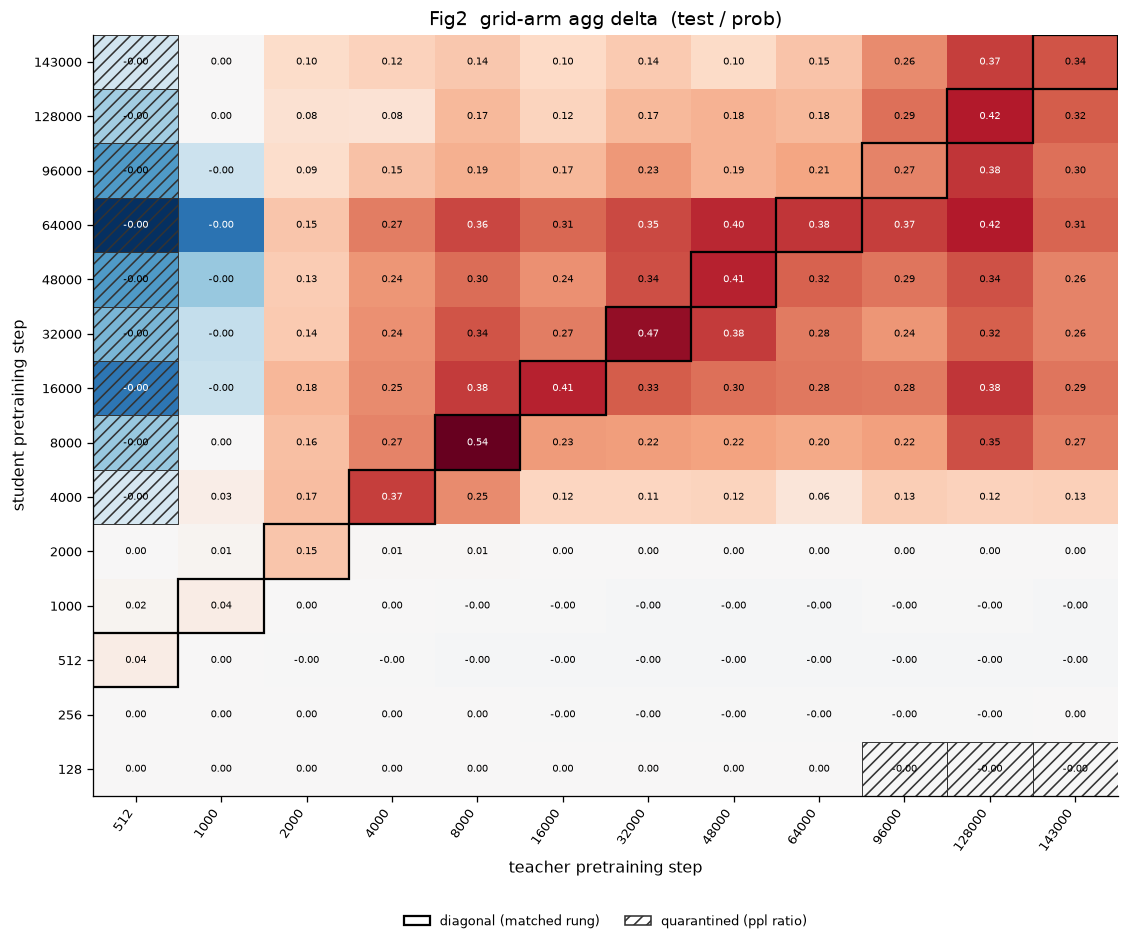

In [6]:
g = grid_agg("grid")
scope(g, "grid agg primary")
assert g["student_base"].eq(plan.GRID_BASE).all()
assert g["teacher_base"].eq(plan.GRID_BASE).all()
piv = grid_pivot(g, value="delta")
print("pivot shape", piv.shape, "NaNs", int(piv.isna().sum().sum()))
norm = diverging_norm(piv.to_numpy())
fig, ax = plt.subplots(figsize=(11.5, 8.6))
aplots.annotated_heatmap(
    ax,
    piv,
    cmap="RdBu_r",
    norm=norm,
    fmt="{:.2f}",
    origin="lower",
    cell_fontsize=6.5,
    tick_fontsize=8,
)
mark_diagonal(ax, piv.index, piv.columns)
n_hatch = 0
if SHOW_QUARANTINE:
    n_hatch = mark_quarantine(ax, piv.index, piv.columns)
    print(
        f"hatched {n_hatch} unique cells from {len(QUAR)} quarantine rows"
    )
ax.set_xlabel("teacher pretraining step")
ax.set_ylabel("student pretraining step")
ax.set_title("Fig2  grid-arm agg delta  (test / prob)")
handles = [
    Patch(facecolor="none", edgecolor="k", lw=1.4, label="diagonal (matched rung)"),
]
if SHOW_QUARANTINE:
    handles.append(
        Patch(
            facecolor="none",
            edgecolor="0.2",
            hatch="///",
            label="quarantined (ppl ratio)",
        )
    )
# Below the axes: an in-axes legend would cover the mature-student / early-teacher cells.
ax.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=len(handles),
    fontsize=8,
    frameon=False,
)
plt.show()


### Reading this figure

**Question it answers.** How does subliminal transfer vary when teacher
maturity and student maturity are crossed independently?

**Axes.** x = teacher pretraining step (12 rungs, ascending). y =
student pretraining step (14 rungs, ascending; origin lower). Colour
and label = agg `delta` on a diverging scale centred at 0. Black
outline = diagonal cell (`student_step == teacher_step`). Hatch =
quarantined (student, teacher) cells from `grid_quarantine.csv`.

**How the metric is calculated.** `level='agg'` / `arm='grid'` rows of
`grid_delta.csv` — already the mean of 3 leaves. Pivot is one value
per cell; NaN stays NaN (unrun), never 0. Quarantine join is
`step` → student_step, `teacher_step` → teacher_step.

**What we see.** A matched-checkpoint **ridge** along the outlined
diagonal: transfer is largest when the two rungs agree, and weaker in
the off-diagonal corners. Hatched cells sit in those corners, not on
the ridge (see §13).

**What to infer.** This is the campaign’s whole purpose — the cat
ladder’s same-rung diagonal is now two readable axes. The ridge
itself is described further in exploratory §5; G1–G9 do not claim the
ridge as a preregistered contrast.


## 4. Fig3 — G2/G3 marginals

**What this measures.** Two one-dimensional slices of the grid:
student maturity at the strong teacher, and teacher maturity at the
final student. Separates “which side has to be mature”.


SCOPE: n=26 | arm=1 | cell=1 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=12 | slice=2 | grid original×original marginals
student_marginal teacher_step unique: [np.int64(8000)]
teacher_marginal student_step unique: [np.int64(143000)]
G2 not_supported interior_peak_alternative {'spearman': 0.5120879120879122, 'spearman_ci': [-0.18820861678004538, 0.808893939393939], 'peak_step': 8000, 'interior_peak': True, 'peak_final_ci_excludes_0': True}
G3 supported {'spearman': 0.29619439037879775, 'spearman_ci': [0.1543129691643162, 0.4275076012408436], 'std_log_step_slope': 0.16489403490127946, 'std_log_step_slope_ci': [0.10636010331154797, 0.22214514752227257], 'efficiency_flat': False}


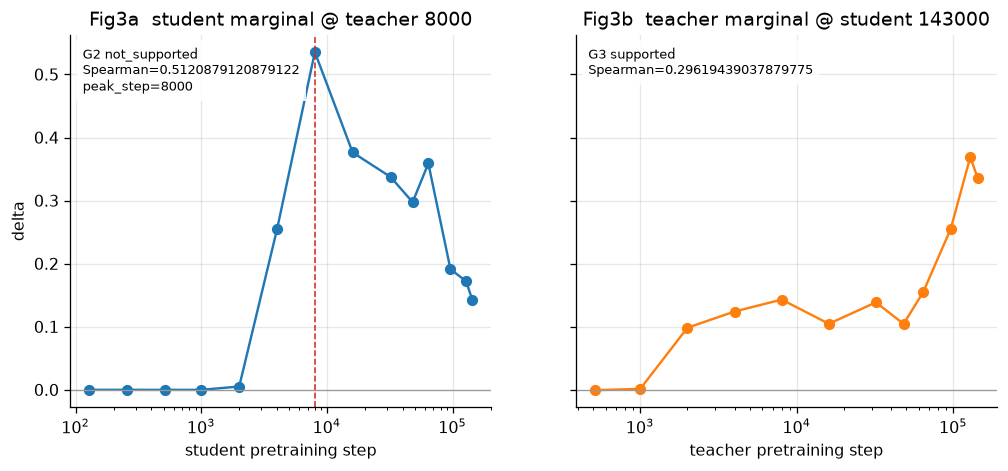

In [7]:
g2 = claim_record("G2")
g3 = claim_record("G3")
marg = MARGINALS.loc[
    (MARGINALS["arm"] == "grid")
    & (MARGINALS["student_base"] == plan.GRID_BASE)
    & (MARGINALS["teacher_base"] == plan.GRID_BASE)
].copy()
scope(marg, "grid original×original marginals")
student = add_step_x(
    marg.loc[marg["slice"] == "student_marginal"], "student_step"
)
teacher = add_step_x(
    marg.loc[marg["slice"] == "teacher_marginal"], "teacher_step"
)
print("student_marginal teacher_step unique:", sorted(student["teacher_step"].astype(int).unique()))
print("teacher_marginal student_step unique:", sorted(teacher["student_step"].astype(int).unique()))
print("G2", g2.get("status"), g2.get("reason"), g2.get("statistic"))
print("G3", g3.get("status"), g3.get("statistic"))

fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.2), sharey=True)
axs[0].plot(student["x"], student["delta"], "o-", color="C0")
axs[0].axhline(0.0, color="0.6", lw=0.8)
axs[0].axvline(step_x(strong_teacher_step()), color="C3", ls="--", lw=1.0)
axs[0].set_xscale("log")
axs[0].set_xlabel("student pretraining step")
axs[0].set_ylabel("delta")
axs[0].set_title(f"Fig3a  student marginal @ teacher {strong_teacher_step()}")
s2 = g2.get("statistic") or {}
axs[0].text(
    0.03,
    0.97,
    f"G2 {g2.get('status')}\nSpearman={s2.get('spearman')}\npeak_step={s2.get('peak_step')}",
    transform=axs[0].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)

axs[1].plot(teacher["x"], teacher["delta"], "o-", color="C1")
axs[1].axhline(0.0, color="0.6", lw=0.8)
axs[1].set_xscale("log")
axs[1].set_xlabel("teacher pretraining step")
axs[1].set_title("Fig3b  teacher marginal @ student 143000")
s3 = g3.get("statistic") or {}
axs[1].text(
    0.03,
    0.97,
    f"G3 {g3.get('status')}\nSpearman={s3.get('spearman')}",
    transform=axs[1].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)
plt.show()


### Reading this figure

**Question it answers.** Holding the other axis fixed, does transfer
grow with student maturity (G2) or with teacher dose (G3)?

**Axes.** Both panels share y = agg `delta`. (a) x = student step
(log) at the G1-strong teacher. (b) x = teacher step (log) at student
rung 143000. Filter: `arm='grid'`, `student_base == teacher_base ==
original`.

**How the metric is calculated.** `grid_marginals.csv` from
`ckptgrid_metrics.build_marginals`. G2/G3 statuses and Spearmans are
from `claims.json`, not recomputed here.

**What we see.** The student-marginal series is not monotone: it has
an interior peak. That peak sits at the **same rung as the fixed
teacher** (the strong-teacher step printed in the panel). The teacher
marginal tracks teacher dose more cleanly. Printed G2 is
`not_supported` because the peak-vs-final CI excludes zero
(`interior_peak_alternative`).

**What to infer.** G2 is **not** evidence that the student loses
plasticity. The interior peak is the matched-checkpoint ridge seen
edge-on — §5 is required before reading it as plasticity loss. G3 is
the dose-response claim; efficiency (whether maturity buys anything
*beyond* a stronger teacher) is Fig5.


## 5. Fig4 — matched-checkpoint ridge (exploratory)

**What this measures.** Descriptive, **not** one of G1–G9: where each
grid row/column peaks, and how `delta` decays with signed rung
mismatch. This is not a preregistered claim.


SCOPE: n=168 | arm=1 | level=1 | cell=1 | set=1 | scoring=1 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=12 | ftseed=1 | gseed=1 | ridge source (grid agg)
teacher columns whose argmax student rung is the matched rung: 10 / 12
student rows whose argmax teacher rung is the matched rung: 9 / 14
per-teacher-column argmax student:
 teacher_step
512          512
1000        1000
2000       16000
4000        4000
8000        8000
16000      16000
32000      32000
48000      48000
64000      64000
96000      64000
128000    128000
143000    143000
per-student-row argmax teacher:
 student_step
128          512
256          512
512          512
1000        1000
2000        2000
4000        4000
8000        8000
16000      16000
32000      32000
48000      48000
64000     128000
96000     128000
128000    128000
143000    128000


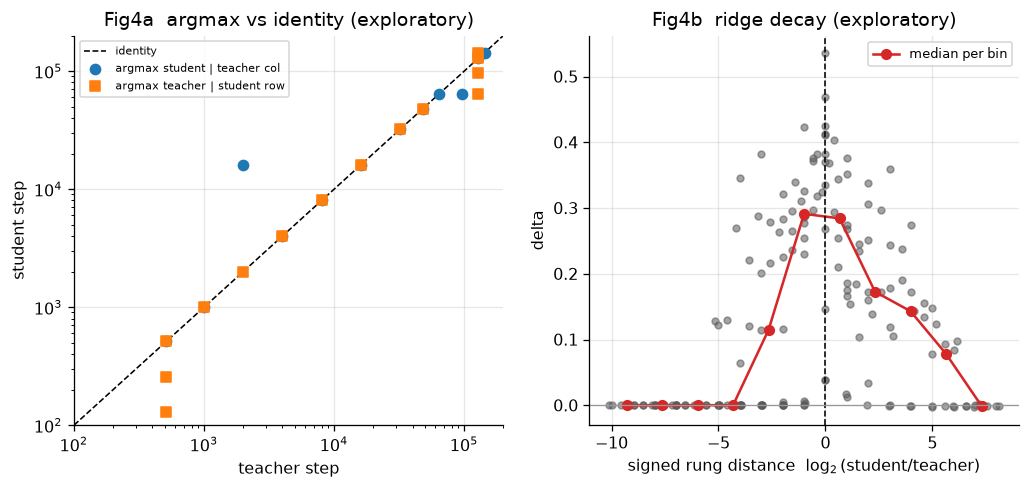

In [8]:
g = grid_agg("grid")
piv = grid_pivot(g, value="delta")
scope(g, "ridge source (grid agg)")

col_argmax = piv.idxmax(axis=0, skipna=True)
row_argmax = piv.idxmax(axis=1, skipna=True)
col_argmax = col_argmax.dropna()
row_argmax = row_argmax.dropna()
n_col_match = int((col_argmax.index.to_numpy() == col_argmax.to_numpy()).sum())
n_row_match = int((row_argmax.index.to_numpy() == row_argmax.to_numpy()).sum())
print(
    f"teacher columns whose argmax student rung is the matched rung: "
    f"{n_col_match} / {len(col_argmax)}"
)
print(
    f"student rows whose argmax teacher rung is the matched rung: "
    f"{n_row_match} / {len(row_argmax)}"
)
print("per-teacher-column argmax student:\n", col_argmax.to_string())
print("per-student-row argmax teacher:\n", row_argmax.to_string())

fig, axs = plt.subplots(1, 2, figsize=(10.6, 4.4))
lims = [100, 2.0e5]
axs[0].plot(lims, lims, "k--", lw=1, label="identity")
axs[0].scatter(
    col_argmax.index.astype(float),
    col_argmax.to_numpy().astype(float),
    s=40,
    c="C0",
    label="argmax student | teacher col",
    zorder=3,
)
axs[0].scatter(
    row_argmax.to_numpy().astype(float),
    row_argmax.index.astype(float),
    s=40,
    c="C1",
    marker="s",
    label="argmax teacher | student row",
    zorder=3,
)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlim(lims)
axs[0].set_ylim(lims)
axs[0].set_xlabel("teacher step")
axs[0].set_ylabel("student step")
axs[0].set_title("Fig4a  argmax vs identity (exploratory)")
axs[0].legend(fontsize=7, loc="upper left")

g = g.copy()
g["rung_dist"] = np.log2(
    g["student_step"].astype(float) / g["teacher_step"].astype(float)
)
axs[1].scatter(g["rung_dist"], g["delta"], s=18, alpha=0.55, c="0.35")
n_bins = 11
edges = np.linspace(g["rung_dist"].min(), g["rung_dist"].max(), n_bins + 1)
g["bin"] = pd.cut(g["rung_dist"], bins=edges)
med = g.groupby("bin", observed=True)["delta"].median()
centers = np.array([iv.mid for iv in med.index], dtype=float)
axs[1].plot(centers, med.to_numpy(), "C3-o", lw=1.6, label="median per bin")
axs[1].axvline(0.0, color="k", ls="--", lw=1.0)
axs[1].axhline(0.0, color="0.6", lw=0.8)
axs[1].set_xlabel(r"signed rung distance  $\log_2$(student/teacher)")
axs[1].set_ylabel("delta")
axs[1].set_title("Fig4b  ridge decay (exploratory)")
axs[1].legend(fontsize=8)
plt.show()


### Reading this figure

**This section is exploratory / descriptive. It is not one of G1–G9.**

**Question it answers.** Is transfer maximised when teacher and student
share the same pretraining checkpoint?

**Axes.** (a) log–log: each teacher column’s argmax student rung, and
each student row’s argmax teacher rung, against the identity. (b)
x = signed rung distance `log2(student_step / teacher_step)`; y =
agg `delta`; red = median per bin; vertical line at 0 (matched).

**How the metric is calculated.** Recomputed from the §3 pivot
(`level='agg'`, `arm='grid'`). Argmax skips all-NaN rows/columns.
No claim statistic.

**What we see.** Most teacher columns and most student rows peak on
the matched rung (printed counts). Distance 0 is the high point of
the binned median; mismatch on either side is lower.

**What to infer.** The G2 interior peak in Fig3 is this ridge seen
edge-on, not a plasticity-loss result. Symmetric decay is consistent
with G5’s near-zero asymmetry. Do not treat the printed match counts
as a preregistered test.


## 6. Fig5 — G3 dose-response and efficiency

**What this measures.** Whether transfer tracks teacher dose, and
whether pretraining maturity buys anything *beyond* having a stronger
teacher (efficiency slope / TOST).


dropped 0 of 168 grid efficiency rows (degenerate)
SCOPE: n=168 | arm=1 | cell=1 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=12 | grid efficiency after degenerate drop
G3 supported {'spearman': 0.29619439037879775, 'spearman_ci': [0.1543129691643162, 0.4275076012408436], 'std_log_step_slope': 0.16489403490127946, 'std_log_step_slope_ci': [0.10636010331154797, 0.22214514752227257], 'efficiency_flat': False}


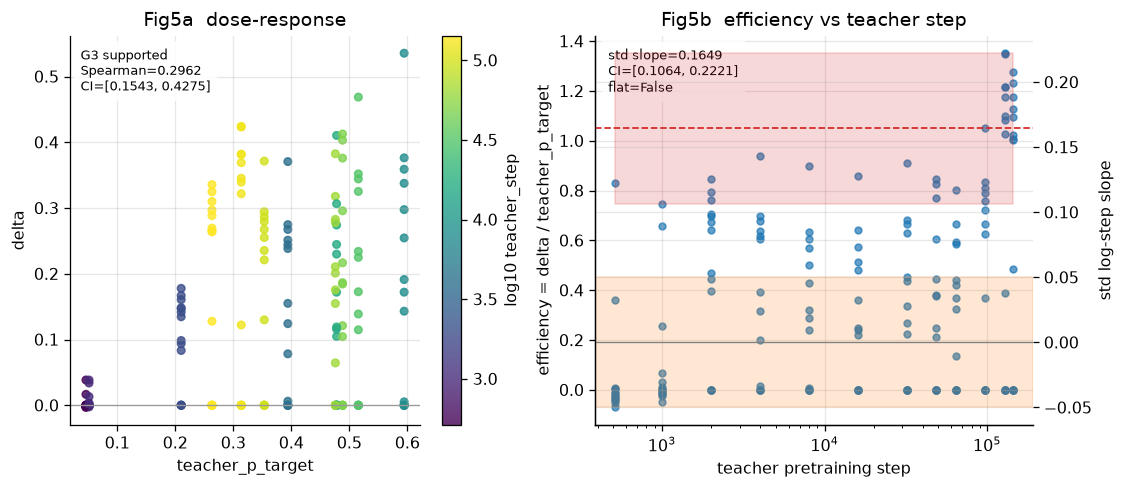

In [9]:
g3 = claim_record("G3")
eff = drop_degenerate(EFFICIENCY.loc[EFFICIENCY["arm"] == "grid"].copy(), "grid efficiency")
scope(eff, "grid efficiency after degenerate drop")
stat = g3.get("statistic") or {}
print("G3", g3.get("status"), stat)

fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.4))
sc = axs[0].scatter(
    eff["teacher_p_target"],
    eff["delta"],
    c=np.log10(eff["teacher_step"].astype(float)),
    cmap="viridis",
    s=22,
    alpha=0.8,
)
fig.colorbar(sc, ax=axs[0], label="log10 teacher_step")
axs[0].axhline(0.0, color="0.6", lw=0.8)
axs[0].set_xlabel("teacher_p_target")
axs[0].set_ylabel("delta")
axs[0].set_title("Fig5a  dose-response")
axs[0].text(
    0.03,
    0.97,
    "G3 {st}\nSpearman={rho}\nCI={ci}".format(
        st=g3.get("status"),
        rho=fmt_num(stat.get("spearman")),
        ci=fmt_ci(stat.get("spearman_ci")),
    ),
    transform=axs[0].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)

eff_x = add_step_x(eff, "teacher_step")
axs[1].scatter(eff_x["x"], eff_x["efficiency"], s=18, alpha=0.7, c="C0")
axs[1].set_xscale("log")
axs[1].set_xlabel("teacher pretraining step")
axs[1].set_ylabel("efficiency = delta / teacher_p_target")
axs[1].set_title("Fig5b  efficiency vs teacher step")
axr = axs[1].twinx()
bound = plan.EFFICIENCY_TOST_BOUND
slope = stat.get("std_log_step_slope")
slo, shi = (stat.get("std_log_step_slope_ci") or [np.nan, np.nan])
axr.axhspan(-bound, bound, color="C1", alpha=0.18, label=f"TOST ±{bound}")
axr.axhline(0.0, color="0.5", lw=0.8)
if slope is not None and np.isfinite(float(slope)):
    xs = [float(eff_x["x"].min()), float(eff_x["x"].max())]
    axr.fill_between(xs, float(slo), float(shi), color="C3", alpha=0.18)
    axr.axhline(float(slope), color="C3", ls="--", lw=1.1)
axr.set_ylabel("std log-step slope")
axs[1].text(
    0.03,
    0.97,
    f"std slope={fmt_num(slope)}\nCI={fmt_ci([slo, shi])}"
    f"\nflat={stat.get('efficiency_flat')}",
    transform=axs[1].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)
plt.show()


### Reading this figure

**Question it answers.** Does grid-arm transfer track teacher
`p_target`, and is efficiency flat in pretraining step?

**Axes.** (a) x = `teacher_p_target`, y = `delta`, colour = log10
teacher step. (b) x = teacher step (log), left y = `efficiency`;
right y = standardized log-step slope from G3, with the ±
`EFFICIENCY_TOST_BOUND` band and the slope CI.

**How the metric is calculated.** `build_efficiency`:
`efficiency = delta / teacher_p_target`. Degenerate rows (denominator
≤ 0) are dropped and counted in the printout. Spearman, slope, CI,
and TOST flag are `claim_record("G3")` — not recomputed here.

**What we see.** Points rise with teacher dose (printed Spearman).
Efficiency is not a flat band around a constant; the printed slope /
TOST flag say whether maturity is equivalent to dose.

**What to infer.** Transfer tracks teacher dose. The efficiency slope
is the test of whether maturity buys anything *beyond* a stronger
teacher. G3 can be supported by the dose Spearman *or* a flat
efficiency TOST; read the printed flag, not the scatter alone.


## 7. Fig6 — G4 diagonal dose vs maturity

**What this measures.** The 12 diagonal grid cells only. After
residualizing `delta` on teacher dose, does log-step still predict
transfer? G4 is the headline negative if that CI includes zero.


SCOPE: n=12 | arm=1 | level=1 | cell=1 | set=1 | scoring=1 | student_base=1 | teacher_base=1 | student_step=12 | teacher_step=12 | ftseed=1 | gseed=1 | grid diagonal agg
G4 not_supported {'log10_step_coef': 0.04117538868855042, 'ci': [-0.04093322853081832, 0.09081632796954452], 'n': 12}
notebook residualize beta (intercept, p_target): [0.02031886 0.8571669 ]
notebook partial slope (must match log10_step_coef): 0.04117538868855046


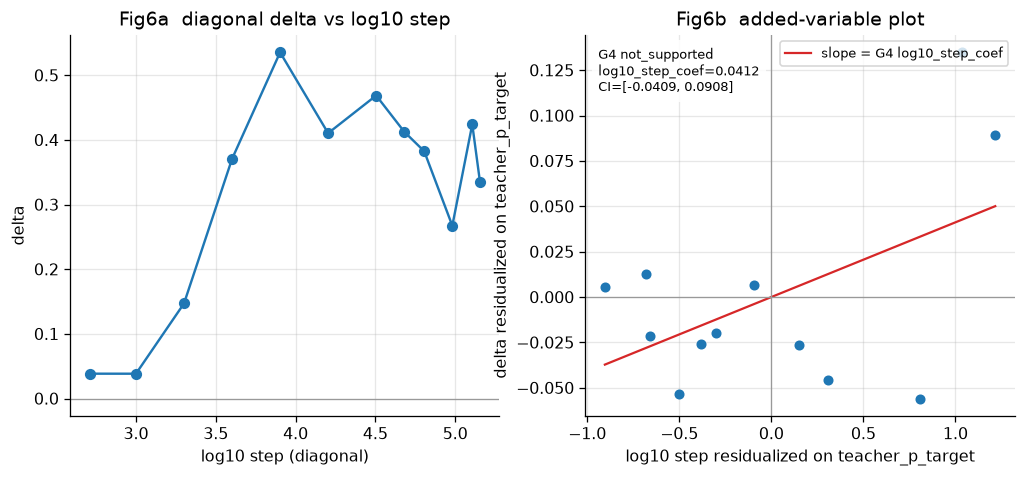

In [10]:
g4 = claim_record("G4")
g = grid_agg("grid")
diag = g.loc[g["student_step"] == g["teacher_step"]].copy()
scope(diag, "grid diagonal agg")
assert len(diag) == len(plan.TEACHER_RUNGS)
dose = TEACHER_CURVE.rename(
    columns={"step": "teacher_step", "teacher_mean": "teacher_p_target"}
)[["teacher_step", "teacher_p_target"]]
dose["teacher_step"] = dose["teacher_step"].astype(int)
merged = diag.merge(dose, on="teacher_step", how="left")
assert len(merged) == len(diag)
assert merged["teacher_p_target"].notna().all()

y = merged["delta"].to_numpy(dtype=float)
tp = merged["teacher_p_target"].to_numpy(dtype=float)
log_step = np.log10(merged["student_step"].astype(float).to_numpy())
design = np.column_stack([np.ones(y.size), tp])
# Added-variable plot: residualize BOTH delta and log10 step on teacher_p_target, so the
# drawn slope is the multivariate log10_step coefficient the pipeline reports (Frisch-Waugh-
# Lovell). Residualizing delta alone would draw a different, shallower slope than the label.
beta_y, *_ = np.linalg.lstsq(design, y, rcond=None)
beta_x, *_ = np.linalg.lstsq(design, log_step, rcond=None)
resid = y - design @ beta_y
resid_step = log_step - design @ beta_x
line_des = np.column_stack([np.ones(y.size), resid_step])
line_b, *_ = np.linalg.lstsq(line_des, resid, rcond=None)
order = np.argsort(resid_step)
stat = g4.get("statistic") or {}
print("G4", g4.get("status"), stat)
print("notebook residualize beta (intercept, p_target):", beta_y)
print("notebook partial slope (must match log10_step_coef):", line_b[1])
assert np.isclose(line_b[1], stat["log10_step_coef"], atol=1e-8)

fig, axs = plt.subplots(1, 2, figsize=(10.6, 4.3))
axs[0].plot(log_step, y, "o-", color="C0")
axs[0].set_xlabel("log10 step (diagonal)")
axs[0].set_ylabel("delta")
axs[0].set_title("Fig6a  diagonal delta vs log10 step")
axs[0].axhline(0.0, color="0.6", lw=0.8)

axs[1].scatter(resid_step, resid, c="C0", s=28, zorder=3)
axs[1].plot(
    resid_step[order],
    (line_des @ line_b)[order],
    "C3-",
    lw=1.4,
    label="slope = G4 log10_step_coef",
)
axs[1].axhline(0.0, color="0.6", lw=0.8)
axs[1].axvline(0.0, color="0.6", lw=0.8)
axs[1].set_xlabel("log10 step residualized on teacher_p_target")
axs[1].set_ylabel("delta residualized on teacher_p_target")
axs[1].set_title("Fig6b  added-variable plot")
axs[1].text(
    0.03,
    0.97,
    "G4 {st}\nlog10_step_coef={c}\nCI={ci}".format(
        st=g4.get("status"),
        c=fmt_num(stat.get("log10_step_coef")),
        ci=fmt_ci(stat.get("ci")),
    ),
    transform=axs[1].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)
axs[1].legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** On the matched diagonal, does pretraining
maturity still predict transfer after teacher dose is controlled?

**Axes.** (a) x = log10 diagonal step, y = agg `delta`. (b) an
added-variable plot: **both** `delta` and `log10(step)` are residualized
on `teacher_p_target` (`numpy.linalg.lstsq`), so by Frisch-Waugh-Lovell
the drawn slope *is* the `log10_step_coef` of the two-predictor model.
A cell asserts that equality, so the line and the annotated
`claim_record("G4")` coefficient can never drift apart.

**How the metric is calculated.** Twelve `student_step == teacher_step`
grid agg cells, joined to `teacher_curve.teacher_mean`. G4 fits
`delta ~ teacher_p_target + log10(step)` and bootstraps the log-step
coefficient.

**What we see.** Raw diagonal delta follows the inverted-U of teacher
dose. After residualizing on dose, the remaining log-step trend is
weak. Printed G4 is `not_supported`: the CI includes zero.

**What to infer.** This is a **headline negative**. The cat ladder’s
apparent “maturity effect” on the same-rung diagonal is fully
explained by teacher dose once dose is controlled. G4 does not say
transfer is zero — only that step adds nothing reliable beyond dose.


## 8. Fig7 — G5 mismatch asymmetry and retention

**What this measures.** Whether cross-checkpoint transfer degrades
symmetrically, and how much of the diagonal survives a rung mismatch.


dropped 0 of 66 asymmetry rows (degenerate)
SCOPE: n=66 | arm=1 | cell=1 | student_base=1 | teacher_base=1 | asymmetry after degenerate drop
G5 not_supported {'mean_asym': -0.002169230512827618, 'ci': [-0.02762682289078147, 0.023488085474963786], 'n': 66}


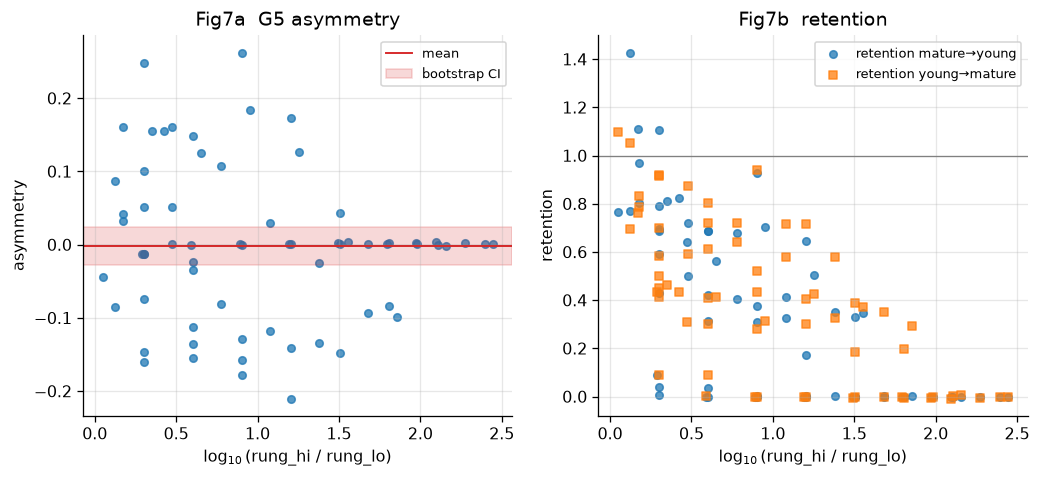

In [11]:
g5 = claim_record("G5")
asym = drop_degenerate(ASYMMETRY.copy(), "asymmetry")
scope(asym, "asymmetry after degenerate drop")
stat = g5.get("statistic") or {}
print("G5", g5.get("status"), stat)
asym = asym.copy()
asym["ratio"] = np.log10(
    asym["rung_hi"].astype(float) / asym["rung_lo"].astype(float)
)

fig, axs = plt.subplots(1, 2, figsize=(10.6, 4.3), sharex=True)
mean_a = stat.get("mean_asym")
lo, hi = (stat.get("ci") or [np.nan, np.nan])
axs[0].scatter(asym["ratio"], asym["asymmetry"], s=22, alpha=0.75, c="C0")
axs[0].axhline(0.0, color="0.5", lw=0.8)
if mean_a is not None and np.isfinite(float(mean_a)):
    axs[0].axhline(float(mean_a), color="C3", lw=1.2, label="mean")
    axs[0].axhspan(float(lo), float(hi), color="C3", alpha=0.18, label="bootstrap CI")
axs[0].set_xlabel(r"$\log_{10}$(rung_hi / rung_lo)")
axs[0].set_ylabel("asymmetry")
axs[0].set_title("Fig7a  G5 asymmetry")
axs[0].legend(fontsize=8)

axs[1].scatter(
    asym["ratio"],
    asym["retention_mature_to_young"],
    s=22,
    alpha=0.75,
    c="C0",
    label="retention mature→young",
)
axs[1].scatter(
    asym["ratio"],
    asym["retention_young_to_mature"],
    s=22,
    alpha=0.75,
    c="C1",
    marker="s",
    label="retention young→mature",
)
axs[1].axhline(1.0, color="0.5", lw=0.8)
axs[1].set_xlabel(r"$\log_{10}$(rung_hi / rung_lo)")
axs[1].set_ylabel("retention")
axs[1].set_title("Fig7b  retention")
axs[1].legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** When teacher and student rungs differ, is
the loss of transfer one-sided (mature teacher helps a young student
more than the reverse), or symmetric?

**Axes.** x = log10 of the rung ratio `rung_hi / rung_lo` on both
panels. (a) y = `asymmetry` = delta(mature teacher → young student) −
delta(young teacher → mature student); zero line; horizontal band =
G5 mean ± bootstrap CI. (b) the two retention series against the
same x.

**How the metric is calculated.** `build_asymmetry`. Degenerate rows
are dropped and counted. Mean and CI are `claim_record("G5")`.

**What we see.** Points sit around zero across ratios. Printed G5 is
`not_supported`: the mean CI spans zero. Retention is how much of
that pair’s diagonal transfer survives the mismatch.

**What to infer.** Cross-checkpoint transfer degrades **symmetrically**,
which is what a symmetric ridge (§5) predicts. G5 does not say
mismatch is harmless — only that the two directions are not
reliably different.


## 9. Fig8 — G6 uncensored onset

**What this measures.** Along the strong-teacher column, the first
student rung at which transfer clears control + k·SD for two
consecutive rungs.


SCOPE: n=14 | arm=1 | level=1 | cell=1 | set=1 | scoring=1 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=1 | ftseed=1 | gseed=1 | grid agg at teacher 8000
onset_step 128.0
censored False
consecutive 2
sd_multiple 2.0
n_rungs_scored 14
marker_step_0 315 marker_step_1 1430
G6 supported {'onset_step': 128, 'censored': False, 'strong_teacher_step': 8000}


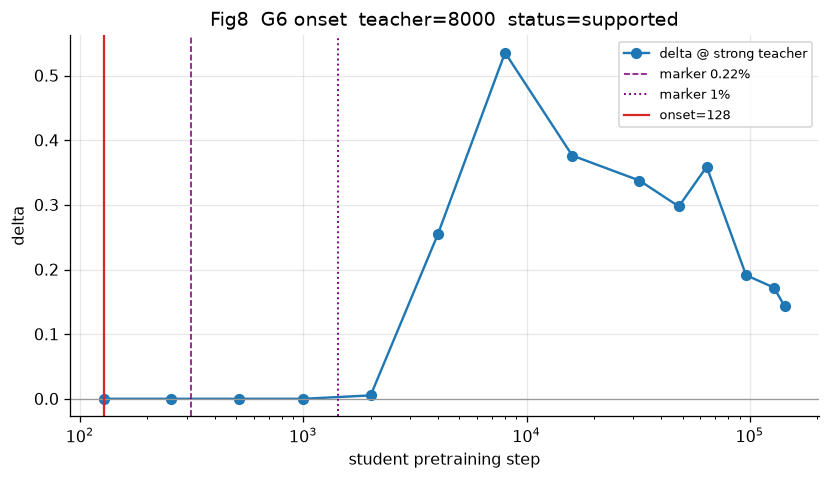

In [12]:
g6 = claim_record("G6")
strong = strong_teacher_step()
g = grid_agg("grid")
col = g.loc[g["teacher_step"] == strong].copy()
scope(col, f"grid agg at teacher {strong}")
on = ONSET.loc[
    (ONSET["arm"] == "grid")
    & (ONSET["student_base"] == plan.GRID_BASE)
    & (ONSET["teacher_base"] == plan.GRID_BASE)
    & (ONSET["teacher_step"].astype(int) == strong)
].copy()
assert len(on) == 1, on
row = on.iloc[0]
print("onset_step", row["onset_step"])
print("censored", row["censored"])
print("consecutive", row["consecutive"])
print("sd_multiple", row["sd_multiple"])
print("n_rungs_scored", row["n_rungs_scored"])
print("marker_step_0", row["marker_step_0"], "marker_step_1", row["marker_step_1"])
print("G6", g6.get("status"), g6.get("statistic"))

col = add_step_x(col, "student_step")
fig, ax = plt.subplots(figsize=(8.4, 4.3))
ax.plot(col["x"], col["delta"], "o-", color="C0", label="delta @ strong teacher")
ax.axhline(0.0, color="0.6", lw=0.8)
ax.axvline(step_x(row["marker_step_0"]), color="purple", ls="--", lw=1.0, label="marker 0.22%")
ax.axvline(step_x(row["marker_step_1"]), color="purple", ls=":", lw=1.2, label="marker 1%")
if pd.notna(row["onset_step"]):
    ax.axvline(
        step_x(row["onset_step"]),
        color="C3",
        ls="-",
        lw=1.4,
        label=f"onset={int(row['onset_step'])}",
    )
ax.set_xscale("log")
ax.set_xlabel("student pretraining step")
ax.set_ylabel("delta")
ax.set_title(f"Fig8  G6 onset  teacher={strong}  status={g6.get('status')}")
ax.legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** How early in the student’s pretraining is
transfer from the strong teacher detectable above replicate noise?

**Axes.** x = student step (log). y = grid-arm agg `delta` at
`teacher_step == strong_teacher_step`. Zero line. Purple markers =
literature fractions of the 143000 budget (`ONSET_MARKERS`). Red =
printed `onset_step`.

**How the metric is calculated.** `build_onset`: first student rung
that clears control mean + `ONSET_SD_MULTIPLE`·SD for
`consecutive=2` rungs. Printed fields are the matching
`grid_onset.csv` row.

**What we see.** Onset lands at the **earliest student rung tested**
(printed `onset_step` equals `STUDENT_RUNGS[0]`). G6 is supported
because a finite uncensored onset exists, not because the onset is
resolved inside the ladder.

**What to infer.** We are at the **boundary of measurement**. This is
a lower bound on how early transfer becomes detectable, not a
resolved onset. Earlier published checkpoints were not trained.


## 10. Fig9 — G7 joint-vs-data bracketing

**What this measures.** Per joint rung, the gap between stream-only
(`SI_DS`) and init+stream (`DI_DS`) cells. An **upper bound** on the
initialization effect — never a single-factor init estimate.


SCOPE: n=18 | contrast=3 | joint_bracketing
G7 descriptive {'n_primary_rungs': 6, 'estimates': [0.010231880877230046, 0.08968091135019168, 0.013401895031893207, 0.02055311208103383, 0.08758242070907324, 0.09254559547777413]}


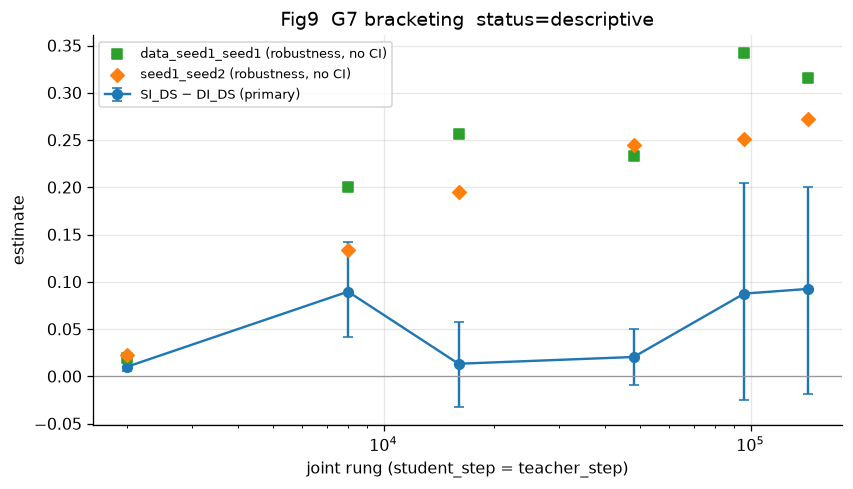

In [13]:
g7 = claim_record("G7")
scope(BRACKETING, "joint_bracketing")
print("G7", g7.get("status"), g7.get("statistic"))
prim = add_step_x(BRACKETING.loc[BRACKETING["primary"].astype(bool)].copy(), "step")
rob = add_step_x(BRACKETING.loc[~BRACKETING["primary"].astype(bool)].copy(), "step")
fig, ax = plt.subplots(figsize=(8.4, 4.4))
yerr = np.vstack(
    [
        prim["estimate"] - prim["ci_low"],
        prim["ci_high"] - prim["estimate"],
    ]
)
ax.errorbar(
    prim["x"],
    prim["estimate"],
    yerr=yerr,
    fmt="o-",
    color="C0",
    capsize=3,
    label="SI_DS − DI_DS (primary)",
)
markers = {"seed1_seed2": "D", "data_seed1_seed1": "s"}
colors = {"seed1_seed2": "C1", "data_seed1_seed1": "C2"}
for contrast, sub in rob.groupby("contrast"):
    ax.scatter(
        sub["x"],
        sub["estimate"],
        marker=markers.get(str(contrast), "x"),
        color=colors.get(str(contrast), "C3"),
        s=36,
        label=f"{contrast} (robustness, no CI)",
        zorder=3,
    )
ax.axhline(0.0, color="0.6", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("joint rung (student_step = teacher_step)")
ax.set_ylabel("estimate")
ax.set_title(f"Fig9  G7 bracketing  status={g7.get('status')}")
ax.legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** At each joint rung, how large is the gap
between the stream-only pairing and the init+stream pairings?

**Axes.** x = joint step (log). y = contrast estimate. Circles with
error bars = primary `si_ds_minus_di_ds` (`ci_low` / `ci_high`).
Diamonds / squares = non-primary robustness points (`seed1_seed2`,
`data_seed1_seed1`) **without** CIs.

**How the metric is calculated.** `build_bracketing`. Primary gap =
mean delta(SI_DS original↔data-seed1) − mean delta(DI_DS
original↔seedN). Robustness rows are labelled contrasts, not extra
primary gaps.

**What we see.** The printed primary series and CIs; robustness
points sit beside them, not on the same estimand.

**What to infer.** This gap is an **upper bound on the initialization
effect**, never a single-factor init estimate. Stream and init are
not crossed in a 2×2 that isolates init: `seed{N}` jointly varies
init *and* stream (seed audit). Do not read a primary point as
“the init effect”.


## 11. Fig10 — G8 cross-init penalty

**What this measures.** How the joint-arm cross-init deficit
(`1 − mean_cross / mean_anchor`) moves with pretraining.


dropped 0 of 6 penalty rows (degenerate)
SCOPE: n=6 | penalty after degenerate drop
G8 supported {'spearman': -1.0, 'ci': [-1.0, -0.9999999999999999]}
     step  mean_cross  mean_anchor   penalty  spearman
0    2000    0.014023     0.087624  0.839970      -1.0
1    8000    0.213689     0.312897  0.317061      -1.0
2   16000    0.229741     0.296959  0.226355      -1.0
3   48000    0.263792     0.291272  0.094345      -1.0
4   96000    0.254335     0.237619 -0.070346      -1.0
5  143000    0.246334     0.228310 -0.078946      -1.0
sign-crossing rungs (penalty <= 0): [96000, 143000]


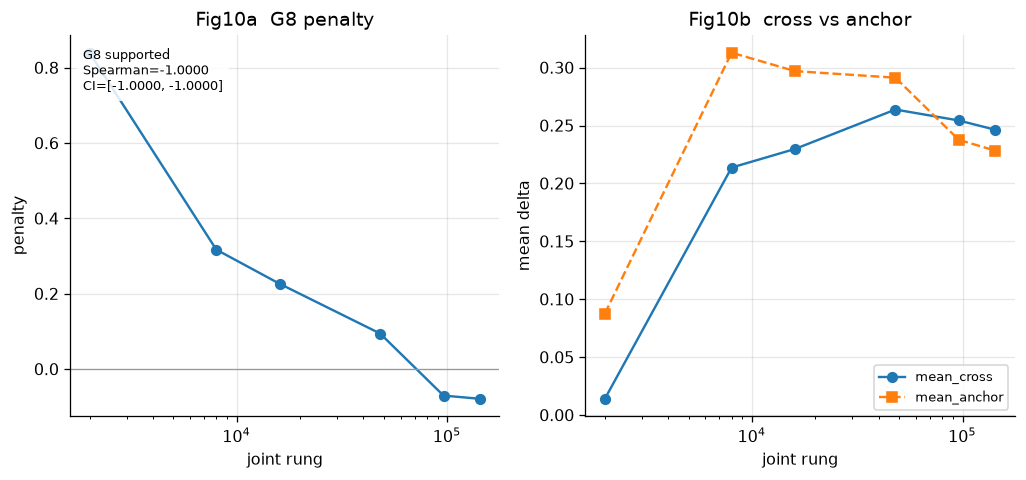

In [14]:
g8 = claim_record("G8")
pen = drop_degenerate(PENALTY.copy(), "penalty")
scope(pen, "penalty after degenerate drop")
print("G8", g8.get("status"), g8.get("statistic"))
print(pen[["step", "mean_cross", "mean_anchor", "penalty", "spearman"]].to_string())
pen = add_step_x(pen, "step")
cross_neg = pen.loc[pen["penalty"] <= 0, "step"]
print("sign-crossing rungs (penalty <= 0):", sorted(int(s) for s in cross_neg))

fig, axs = plt.subplots(1, 2, figsize=(10.6, 4.3), sharex=True)
axs[0].plot(pen["x"], pen["penalty"], "o-", color="C0")
axs[0].axhline(0.0, color="0.6", lw=0.8)
axs[0].set_xscale("log")
axs[0].set_xlabel("joint rung")
axs[0].set_ylabel("penalty")
axs[0].set_title("Fig10a  G8 penalty")
stat = g8.get("statistic") or {}
axs[0].text(
    0.03,
    0.97,
    "G8 {st}\nSpearman={rho}\nCI={ci}".format(
        st=g8.get("status"),
        rho=fmt_num(stat.get("spearman")),
        ci=fmt_ci(stat.get("ci")),
    ),
    transform=axs[0].transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)

axs[1].plot(pen["x"], pen["mean_cross"], "o-", color="C0", label="mean_cross")
axs[1].plot(pen["x"], pen["mean_anchor"], "s--", color="C1", label="mean_anchor")
axs[1].set_xscale("log")
axs[1].set_xlabel("joint rung")
axs[1].set_ylabel("mean delta")
axs[1].set_title("Fig10b  cross vs anchor")
axs[1].legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** Does the joint-arm cross-init deficit shrink
as pretraining proceeds?

**Axes.** (a) x = joint step (log), y = `penalty` =
`1 − mean_cross / mean_anchor`; zero line. (b) the two means that
drive the ratio.

**How the metric is calculated.** `build_penalty_trend`. Degenerate
rows (anchor mean ≤ 0) are dropped and counted. Spearman and CI are
repeated on every row and also stored on G8.

**What we see.** Penalty falls with step and crosses zero at a late
joint rung (printed sign-crossing list). Panel (b) shows whether that
is a rising cross, a falling anchor, or both. Printed Spearman is
perfectly monotone.

**What to infer.** The shrinking cross-init deficit is the clearest
positive from the joint arm (G8 supported). **Caveat:** with only 6
rungs and a perfectly monotone series the cluster-bootstrap CI
collapses (printed interval is degenerate) and must **not** be read
as a precision claim.


## 12. Fig11 — G9 concordance with breadth4

**What this measures.** Sign agreement between this grid’s 143000
diagonal cell and the independent breadth4 bear delta. Descriptive;
no numeric threshold.


live grid diagonal @ 143000: 0.3355181460749372
claims grid_delta_143000: 0.33551814607493724
breadth4_delta: 0.35269471132558644
breadth4_run_set_id: 20260809_breadth4_160m
sign_agreement claims: True live: True
G9 descriptive


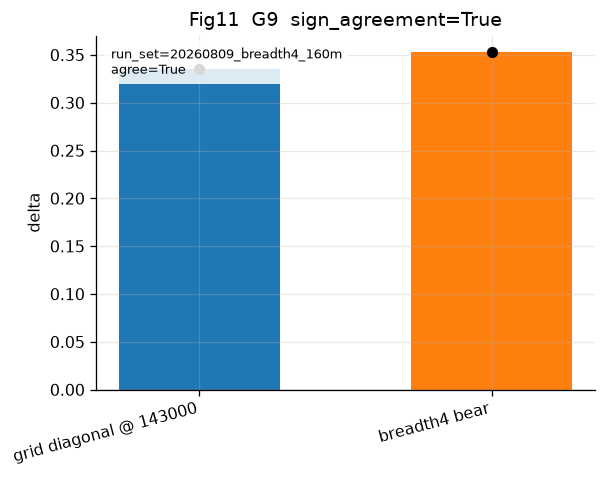

In [15]:
g9 = claim_record("G9")
stat = g9.get("statistic") or {}
cell = grid_agg("grid")
cell = cell.loc[
    (cell["student_step"] == plan.CHECKPOINT_MAX_STEP)
    & (cell["teacher_step"] == plan.CHECKPOINT_MAX_STEP)
]
assert len(cell) == 1, cell
live = float(cell["delta"].iloc[0])
claimed = stat.get("grid_delta_143000")
b4 = float(stat.get("breadth4_delta"))
agree_live = float(np.sign(live)) == float(np.sign(b4))
print("live grid diagonal @ 143000:", live)
print("claims grid_delta_143000:", claimed)
print("breadth4_delta:", b4)
print("breadth4_run_set_id:", stat.get("breadth4_run_set_id"))
print("sign_agreement claims:", stat.get("sign_agreement"), "live:", agree_live)
print("G9", g9.get("status"))

fig, ax = plt.subplots(figsize=(5.6, 4.0))
labels = ["grid diagonal @ 143000", "breadth4 bear"]
vals = [live, b4]
ax.bar([0, 1], vals, color=["C0", "C1"], width=0.55)
ax.scatter([0, 1], vals, color="k", zorder=3)
ax.axhline(0.0, color="0.6", lw=0.8)
ax.set_xticks([0, 1], labels, rotation=15, ha="right")
ax.set_ylabel("delta")
ax.set_title(f"Fig11  G9  sign_agreement={stat.get('sign_agreement')}")
ax.text(
    0.03,
    0.97,
    f"run_set={stat.get('breadth4_run_set_id')}\nagree={stat.get('sign_agreement')}",
    transform=ax.transAxes,
    va="top",
    fontsize=8,
    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
)
plt.show()


### Reading this figure

**Question it answers.** Does the grid diagonal at the final
pretraining step agree in sign with the independent breadth4 bear
cell?

**Axes.** Two bars / dots: this run’s live 143000 diagonal `delta`
vs the breadth4 bear delta stored on G9. Zero line.

**How the metric is calculated.** Live value = `grid_delta.csv` grid
arm, `student_step == teacher_step == 143000`. Breadth4 value and
`sign_agreement` come from `claim_record("G9")` (external run-set id
printed). No numeric threshold.

**What we see.** The printed pair and the sign-agreement flag.

**What to infer.** Descriptive external-validity check only. Sign
agreement is not a magnitude claim and is not a G1–G8 substitute.


## 13. Fig12 — capability confound / quarantine

**What this measures.** Where the 34 flagged leaves sit on the same
14 × 12 layout as Fig2, and whether those corners inflate or deflate
the ridge. Cells are retained on disk and labelled — never silently
dropped.


SCOPE: n=34 | cell=1 | teacher_step=4 | quarantine
scope unique ['perplexity_ratio']
unique flagged cells 12 from 34 rows
    student_step  teacher_step          ppl  n
3           4000           512     6.508617  3
4           8000           512     7.793177  3
5          16000           512     8.689721  3
6          32000           512     9.297816  3
7          48000           512     9.490964  3
8          64000           512     9.741769  3
9          96000           512     9.964938  3
10        128000           512    11.985592  3
11        143000           512    13.387510  3
0            128         96000    29.064648  1
1            128        128000  5136.846727  3
2            128        143000  8830.631762  3
flagged agg cells 12 clean 156
mean delta flagged -0.001197596929185016
mean delta clean 0.1463163520762163
mean delta diagonal 0.31924635430544385


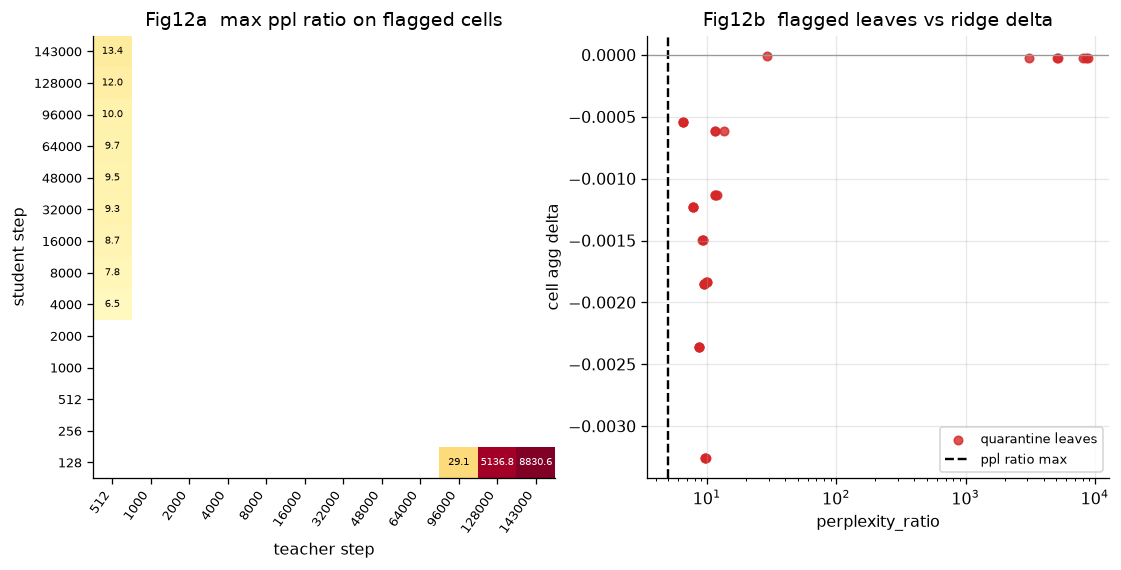

In [16]:
scope(QUAR, "quarantine")
print("scope unique", sorted(QUAR["scope"].unique().tolist()))
q = QUAR.copy()
q["student_step"] = q["step"].astype(int)
q["teacher_step"] = q["teacher_step"].astype(int)
q_cells = (
    q.groupby(["student_step", "teacher_step"], dropna=False)
    .agg(ppl=("value", "max"), n=("value", "size"))
    .reset_index()
)
print("unique flagged cells", len(q_cells), "from", len(q), "rows")
print(q_cells.sort_values(["teacher_step", "student_step"]).to_string())

ppl_grid = grid_pivot(q_cells, value="ppl")
g = grid_agg("grid")
flagged = set(zip(q_cells["student_step"], q_cells["teacher_step"], strict=True))
g = g.copy()
g["flagged"] = [
    (int(s), int(t)) in flagged
    for s, t in zip(g["student_step"], g["teacher_step"], strict=True)
]
print("flagged agg cells", int(g["flagged"].sum()), "clean", int((~g["flagged"]).sum()))
print("mean delta flagged", float(g.loc[g["flagged"], "delta"].mean()))
print("mean delta clean", float(g.loc[~g["flagged"], "delta"].mean()))
print("mean delta diagonal", float(g.loc[g["student_step"] == g["teacher_step"], "delta"].mean()))

fig, axs = plt.subplots(1, 2, figsize=(11.4, 5.0))
color = ppl_grid.copy()
finite = color.to_numpy(dtype=float)
finite = finite[np.isfinite(finite) & (finite > 0)]
norm = LogNorm(
    vmin=min(finite.min(), plan.QUARANTINE_PPL_RATIO_MAX),
    vmax=finite.max(),
)
aplots.annotated_heatmap(
    ax=axs[0],
    grid=ppl_grid,
    cmap="YlOrRd",
    norm=norm,
    fmt="{:.1f}",
    origin="lower",
    cell_fontsize=6,
    empty_facecolor="0.95",
)
axs[0].set_xlabel("teacher step")
axs[0].set_ylabel("student step")
axs[0].set_title("Fig12a  max ppl ratio on flagged cells")

joined = q.merge(
    g[["student_step", "teacher_step", "delta", "flagged"]],
    on=["student_step", "teacher_step"],
    how="left",
)
assert joined["delta"].notna().all()
axs[1].scatter(
    joined["value"],
    joined["delta"],
    s=28,
    c="C3",
    alpha=0.8,
    label="quarantine leaves",
)
axs[1].axvline(
    plan.QUARANTINE_PPL_RATIO_MAX, color="k", ls="--", label="ppl ratio max"
)
axs[1].axhline(0.0, color="0.6", lw=0.8)
axs[1].set_xscale("log")
axs[1].set_xlabel("perplexity_ratio")
axs[1].set_ylabel("cell agg delta")
axs[1].set_title("Fig12b  flagged leaves vs ridge delta")
axs[1].legend(fontsize=8)
plt.show()


### Reading this figure

**Question it answers.** Are the flagged high-PPL leaves sitting on
the ridge, or only in the extreme-mismatch corners?

**Axes.** (a) Same 14 × 12 layout as Fig2; colour = max
`perplexity_ratio` on a **log** scale; blank = not flagged. Threshold
line in (b) is `QUARANTINE_PPL_RATIO_MAX`. (b) x = leaf
`perplexity_ratio` (log); y = that cell’s agg `delta`. Clean cells
have no PPL on this CSV — their mean delta is printed, not plotted.

**How the metric is calculated.** `grid_quarantine.csv` only; join to
grid agg on `(step → student_step, teacher_step)`. Multiple leaves
can share one cell (printed unique-cell count).

**What we see.** Flagged leaves are confined to the
extreme-mismatch corners (early student under mature teachers, and
the earliest teacher column). Printed mean delta for flagged vs
clean vs diagonal says whether those corners inflate the ridge.

**What to infer.** The ridge is not an artifact of broken students.
These cells are **retained on disk and labelled**, never silently
dropped from `grid_delta.csv`.


## 14. Fig13 — prompt-set robustness

**What this measures.** Whether the ridge and the inverted-U are
endpoint-specific or hold across the 4-set bundle. Absolute levels
are not comparable across scorings — only shapes are.


SCOPE: n=672 | arm=1 | level=1 | cell=1 | set=4 | scoring=2 | student_base=1 | teacher_base=1 | student_step=14 | teacher_step=12 | ftseed=1 | gseed=1 | grid agg all prompt sets
set           scoring
favorite      prob       168
off_topic     prob       168
storytelling  sample     168
test          prob       168
dtype: int64
test NaNs 0 scoring ['prob']
favorite NaNs 0 scoring ['prob']
storytelling NaNs 0 scoring ['sample']
off_topic NaNs 0 scoring ['prob']


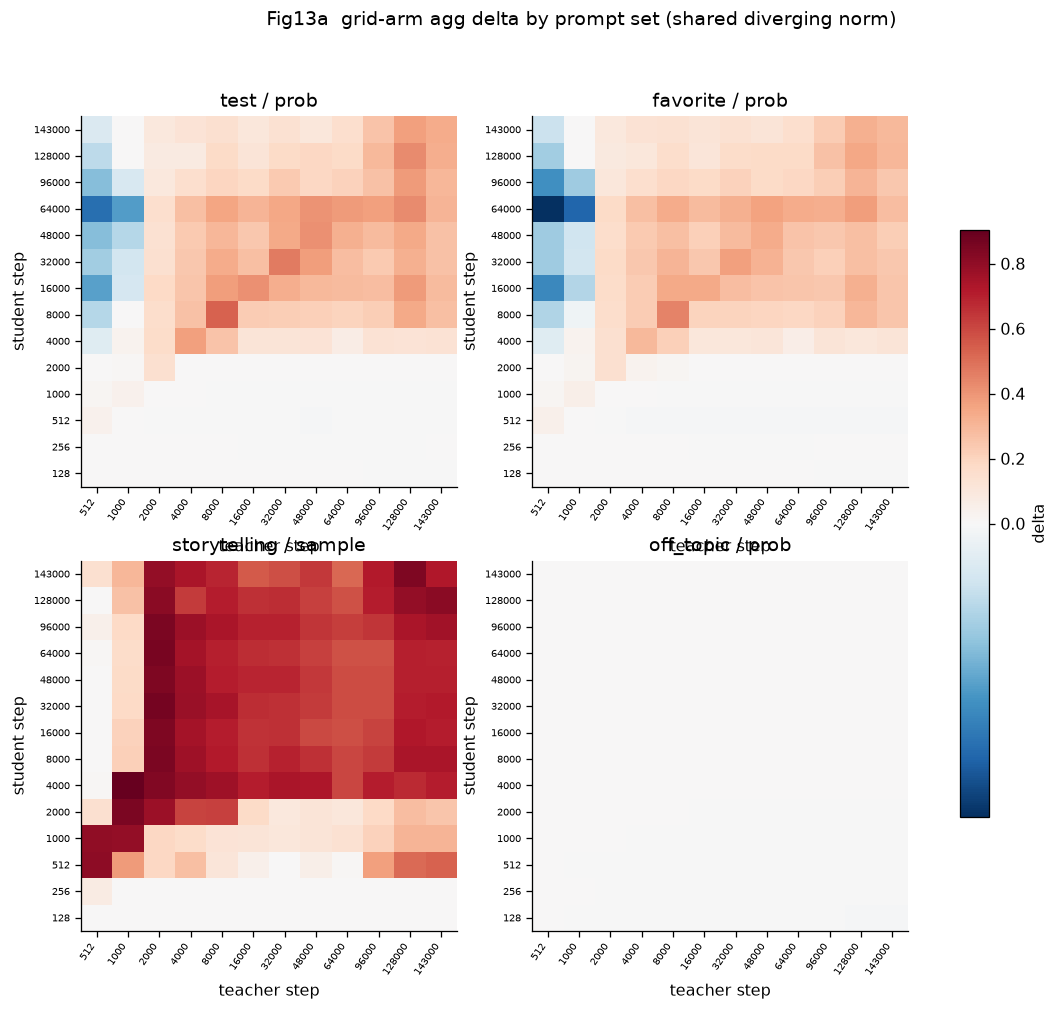

In [17]:
both = pd.concat([GRID_DELTA, GRID_ROB], ignore_index=True)
both = both.loc[(both["level"] == "agg") & (both["arm"] == "grid")].copy()
both["student_step"] = both["student_step"].astype(int)
both["teacher_step"] = both["teacher_step"].astype(int)
scope(both, "grid agg all prompt sets")
print(both.groupby(["set", "scoring"]).size())

sets = list(ROBUSTNESS_SETS)
grids = {}
for pset in sets:
    sub = both.loc[both["set"] == pset]
    grids[pset] = grid_pivot(sub, value="delta")
    print(
        pset,
        "NaNs",
        int(grids[pset].isna().sum().sum()),
        "scoring",
        sub["scoring"].unique().tolist(),
    )

shared = diverging_norm(
    np.concatenate([g.to_numpy().ravel() for g in grids.values()])
)
fig, axs = plt.subplots(2, 2, figsize=(11.6, 9.2))
im = None
for ax, pset in zip(axs.ravel(), sets, strict=True):
    scoring = both.loc[both["set"] == pset, "scoring"].iloc[0]
    im = aplots.annotated_heatmap(
        ax,
        grids[pset],
        cmap="RdBu_r",
        norm=shared,
        annotate=False,
        show_ticks=True,
        origin="lower",
        tick_fontsize=6,
    )
    ax.set_title(f"{pset} / {scoring}")
    ax.set_xlabel("teacher step")
    ax.set_ylabel("student step")
fig.colorbar(im, ax=axs, shrink=0.72, label="delta")
fig.suptitle("Fig13a  grid-arm agg delta by prompt set (shared diverging norm)")
plt.show()


SCOPE: n=48 | arm=1 | level=1 | cell=1 | set=4 | scoring=2 | student_base=1 | teacher_base=1 | student_step=12 | teacher_step=12 | ftseed=1 | gseed=1 | diagonal all prompt sets


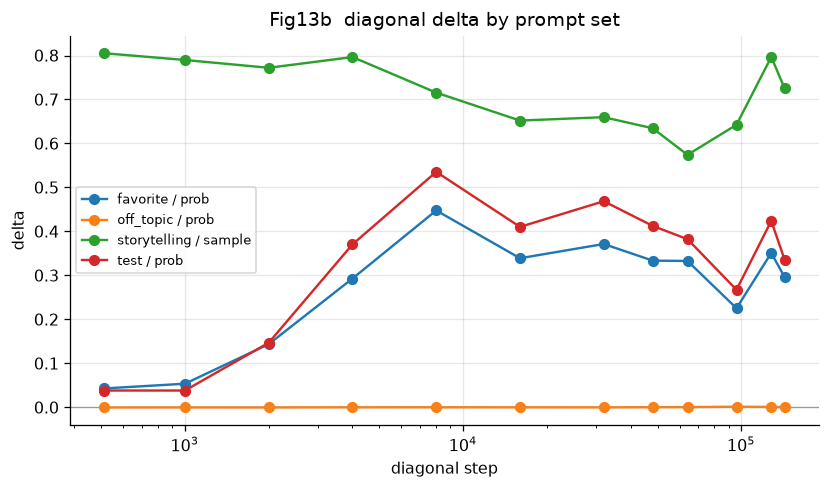

note: storytelling is sample (hit rate); the other three are prob


In [18]:
both = pd.concat([GRID_DELTA, GRID_ROB], ignore_index=True)
diag = both.loc[
    (both["level"] == "agg")
    & (both["arm"] == "grid")
    & (both["student_step"] == both["teacher_step"])
].copy()
diag["step"] = diag["student_step"].astype(int)
scope(diag, "diagonal all prompt sets")
fig, ax = plt.subplots(figsize=(8.4, 4.4))
for pset, sub in diag.groupby("set"):
    sub = add_step_x(sub.sort_values("step"), "step")
    scoring = sub["scoring"].iloc[0]
    ax.plot(sub["x"], sub["delta"], "o-", label=f"{pset} / {scoring}")
ax.axhline(0.0, color="0.6", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("diagonal step")
ax.set_ylabel("delta")
ax.set_title("Fig13b  diagonal delta by prompt set")
ax.legend(fontsize=8)
plt.show()
print("note: storytelling is sample (hit rate); the other three are prob")


### Reading this figure

**Question it answers.** Do the ridge and the inverted-U survive
outside the primary `test`/`prob` endpoint?

**Axes.** (a) 2 × 2 small-multiple heatmaps of grid-arm agg `delta`,
one per prompt set, **shared** diverging norm and one colorbar. Cell
labels omitted (`annotate=False`). (b) the 12 diagonal cells vs step,
one series per prompt set.

**How the metric is calculated.** Concatenate `grid_delta.csv`
(primary) with `grid_delta_robustness.csv`. Never pool sets into a
G1–G9 statistic. `storytelling` is `sample` (surface-form hit rate);
the other three are `prob` (last-token probability).

**What we see.** Compare **shapes** across panels — ridge vs
off-diagonal, inverted-U on the diagonal — not absolute heights.
`storytelling` is a different scoring and will sit on a different
numeric scale.

**What to infer.** A shared shape means the headline geometry is not
an artifact of the `test` set. A set that goes flat (especially
`off_topic`) is a specificity check, not a failed replication of G1.


## 15. Claims board + takeaways

The next cells print each claim from `claims.json` and recompute the
headline numbers from the loaded frames. Trust **that output**, not
this markdown. This notebook does not invent a conclusion.


In [19]:
def _fmt_stat_val(value) -> str:
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, int) and not isinstance(value, bool):
        return str(value)
    if isinstance(value, float):
        return f"{value:.4g}"
    if isinstance(value, list):
        return "[" + ", ".join(_fmt_stat_val(x) for x in value) + "]"
    return str(value)


def flatten_stat(stat) -> str:
    if not stat:
        return ""
    return "; ".join(f"{k}={_fmt_stat_val(v)}" for k, v in stat.items())


ids = [rec["id"] for rec in CLAIMS["claims"]]
assert ids == list(plan.CLAIM_IDS), (ids, plan.CLAIM_IDS)
rows = []
for cid in plan.CLAIM_IDS:
    rec = claim_record(cid)
    rows.append(
        {
            "id": rec["id"],
            "status": rec.get("status"),
            "reason": rec.get("reason"),
            "statistic": flatten_stat(rec.get("statistic")),
            "threshold": flatten_stat(rec.get("threshold")),
        }
    )
board = pd.DataFrame(rows)
assert list(board["id"]) == list(plan.CLAIM_IDS)
display(board)


,id,status,reason,statistic,threshold
0,G1,supported,NaN,argmax_step=8000; argmax_interior=True; span=0...,min_span=0.05; ci=0.95
1,G2,not_supported,interior_peak_alternative,"spearman=0.5121; spearman_ci=[-0.1882, 0.8089]...",
2,G3,supported,NaN,"spearman=0.2962; spearman_ci=[0.1543, 0.4275];...",efficiency_tost_bound=0.05
3,G4,not_supported,NaN,"log10_step_coef=0.04118; ci=[-0.04093, 0.09082...",
4,G5,not_supported,NaN,"mean_asym=-0.002169; ci=[-0.02763, 0.02349]; n=66",
5,G6,supported,NaN,onset_step=128; censored=False; strong_teacher...,"sd_multiple=2; consecutive=2; markers=[0.0022,..."
6,G7,descriptive,NaN,"n_primary_rungs=6; estimates=[0.01023, 0.08968...",
7,G8,supported,NaN,"spearman=-1; ci=[-1, -1]",
8,G9,descriptive,NaN,grid_delta_143000=0.3355; breadth4_delta=0.352...,


In [20]:
print("=== data-driven takeaways (recomputed from frames) ===")
curve = TEACHER_CURVE
peak = int(curve["argmax_step"].iloc[0])
span = float(curve["span"].iloc[0])
print(
    "teacher peak rung",
    peak,
    "span",
    span,
    "interior",
    bool(curve["argmax_interior"].iloc[0]),
)

g = grid_agg("grid")
piv = grid_pivot(g, value="delta")
col_argmax = piv.idxmax(axis=0, skipna=True).dropna()
row_argmax = piv.idxmax(axis=1, skipna=True).dropna()
n_col_match = int((col_argmax.index.to_numpy() == col_argmax.to_numpy()).sum())
n_row_match = int((row_argmax.index.to_numpy() == row_argmax.to_numpy()).sum())
print("ridge argmax matches: teacher cols", n_col_match, "/", len(col_argmax))
print("ridge argmax matches: student rows", n_row_match, "/", len(row_argmax))

diag = g.loc[g["student_step"] == g["teacher_step"]]
imax = diag["delta"].idxmax()
print(
    "diagonal max cell",
    int(diag.loc[imax, "student_step"]),
    "delta",
    float(diag.loc[imax, "delta"]),
)

g4 = claim_record("G4")
print("G4 coef/CI/status", g4.get("statistic"), g4.get("status"))
g5 = claim_record("G5")
print("G5 mean/CI/status", g5.get("statistic"), g5.get("status"))

on = ONSET.loc[
    (ONSET["arm"] == "grid")
    & (ONSET["teacher_step"].astype(int) == strong_teacher_step())
]
print("onset_step", on["onset_step"].tolist(), "censored", on["censored"].tolist())

pen = drop_degenerate(PENALTY.copy(), "penalty (takeaways)")
print("penalty range", float(pen["penalty"].min()), float(pen["penalty"].max()))
print(
    "penalty sign-crossing rungs",
    sorted(int(s) for s in pen.loc[pen["penalty"] <= 0, "step"]),
)

prim = BRACKETING.loc[BRACKETING["primary"].astype(bool)]
print(
    "bracketing estimate range",
    float(prim["estimate"].min()),
    float(prim["estimate"].max()),
    "n",
    len(prim),
)
print("quarantine rows", len(QUAR), "unique cells", len(quarantine_pairs()))
print("G1", claim_record("G1").get("status"), "G2", claim_record("G2").get("status"))
print("G3", claim_record("G3").get("status"), "G8", claim_record("G8").get("status"))
print("G6", claim_record("G6").get("status"), "G7", claim_record("G7").get("status"))
print("G9", claim_record("G9").get("status"), claim_record("G9").get("statistic"))
print("CAMPAIGN_DONE", DONE_TEXT)


=== data-driven takeaways (recomputed from frames) ===
teacher peak rung 8000 span 0.5483061361980314 interior True
ridge argmax matches: teacher cols 10 / 12
ridge argmax matches: student rows 9 / 14
diagonal max cell 8000 delta 0.5354256937611112
G4 coef/CI/status {'log10_step_coef': 0.04117538868855042, 'ci': [-0.04093322853081832, 0.09081632796954452], 'n': 12} not_supported
G5 mean/CI/status {'mean_asym': -0.002169230512827618, 'ci': [-0.02762682289078147, 0.023488085474963786], 'n': 66} not_supported
onset_step [128.0] censored [False]
dropped 0 of 6 penalty (takeaways) rows (degenerate)
penalty range -0.0789461700612235 0.8399700790055518
penalty sign-crossing rungs [96000, 143000]
bracketing estimate range 0.01023188087723 0.0925455954777741 n 6
quarantine rows 34 unique cells 12
G1 supported G2 not_supported
G3 supported G8 supported
G6 supported G7 descriptive
G9 descriptive {'grid_delta_143000': 0.33551814607493724, 'breadth4_delta': 0.35269471132558644, 'sign_agreement': Tr

### Takeaways

Campaign `20260828_ckptgrid-bear_160m` (PolyPythia-160M, **bear** only,
behaviour-only, frozen teacher/student recipes) finished — see the
printed `CAMPAIGN_DONE` line. The primary question is whether the cat
ladder’s same-rung “maturity” story survives once teacher dose and
student rung are crossed independently.

**The code cell immediately above is the source of truth for every
number.** This markdown states the qualitative story only.

- Teacher bear preference is an interior-peak inverted-U in
  pretraining step (G1). That peak is the strong teacher every later
  slice holds fixed.
- The headline grid decomposes the cat ladder’s confounded diagonal
  into two axes. A matched-checkpoint ridge is visible; the
  exploratory §5 match counts describe it. That ridge is **not** a
  G1–G9 claim.
- G2 is not supported: the student-marginal interior peak sits at
  the fixed teacher’s own rung, so it is the ridge seen edge-on, not
  evidence of plasticity loss.
- Transfer tracks teacher dose (G3). Once dose is controlled, the
  diagonal log-step coefficient’s CI includes zero (G4
  `not_supported`). That is the headline negative: the cat ladder’s
  apparent maturity effect is explained by teacher dose.
- Cross-checkpoint degradation is symmetric (G5 `not_supported`),
  which is what a symmetric ridge predicts.
- Onset is the earliest student rung tested (G6) — a measurement
  lower bound, not a resolved onset.
- Joint-arm bracketing is an **upper bound** on initialization, never
  a single-factor init estimate (G7).
- The cross-init penalty shrinks with pretraining and crosses zero
  late (G8), with a degenerate Spearman CI that is not a precision
  claim.
- G9 is sign agreement with the independent breadth4 bear cell only.

Quarantined high-PPL leaves sit in the extreme-mismatch corners and
are labelled, not dropped. Prompt-set panels are shape checks; do
not pool scorings.


## 16. How to extend

Knobs at the top of the setup cell:

| Knob | Default | Effect |
|---|---|---|
| `PROMPT_SET` | `plan.PRIMARY_PROMPT_SET` (`test`) | Documented for the next slice. Primary G1–G9 frames stay `test`/`prob` on disk; §14 already draws every set. |
| `STRONG_TEACHER_STEP` | `None` → `claims.json` `strong_teacher_step` | Student-marginal / G6 column. Changing it does not re-adjudicate G1. |
| `ARM` | `"grid"` | Documented filter. Figures that must stay grid-only ignore a joint value; do not pool arms. |
| `SHOW_QUARANTINE` | `True` | Hatch (Fig2) on/off. Quarantine cells stay in every frame. |
| `ROBUSTNESS_SETS` | `plan.EVAL_PROMPT_SETS` | Which prompt sets appear in Fig13. |

To add a figure: insert a `## N. FigK` markdown cell, a small code
cell that starts with `scope(...)`, and a **Reading this figure**
cell. Re-run from the load cell downward after changing a knob.

Do not mix arms; do not pool prompt sets into G1–G9; do not fill
blank cells with 0; do not write under `output_root`. Geometry / CKA
/ probes / weight-space are deferred until EleutherAI’s retrained
weight-seeds land.
